# Tecnológico de Monterrey

**Maestría en Inteligencia Artificial Aplicada**  
**Proyecto Integrador — Avance 4: Modelos Alternativos**  
**Proyecto:** Multipricing para Cash Management / Global Transaction Banking (GTB)  
**Equipo 9 — Cash Optimization**  
**Profesor:** Dr. Horacio Martinez Alfaro

| Integrante | Matrícula |
|---|---|
| Oscar Benjamín Zacarías Villegas | A01797160 |
| Mariana Paola De los Cobos Kingston | A01796922 |
| Gerardo Tenorio Castillo | A01139576 |



-------
## Seguimiento del Avance 3

### 1. ¿Por qué un modelo más preciso al resolver su objetivo puede tener peor MAE?

Precisión numérica y precisión predictiva son temas que se analizaron para escoger realmente al candidato ganador, siendo que  la primera indica qué tan bien se resolvió el problema de entrenamiento, mientras que la segunda se observa al pronosticar datos posteriores.

Ridge minimiza una suma de errores **cuadráticos** más una penalización sobre sus coeficientes, no minimiza directamente MAE. Resolver mejor ese objetivo puede producir coeficientes distintos y empeorar el MAE futuro.

En los resultados de E3 observamos que Ridge A obtuvo MAE **501.84**, frente a **399.78** de persistencia. Al exigir una solución numérica más precisa disminuyó el objetivo de entrenamiento, pero empeoró el resultado de Validation. La detención temprana pudo actuar como regularización implícita, esto es una explicación posible, no una prueba de causalidad. Un buen MAE tampoco demuestra convergencia.

Por tanto, no terminamos eligiendo Ridge no convergido como solución operativa. Se conservó como referencia histórica reproducible, sin interpretar sus coeficientes como evidencia final.

### 2. ¿Por qué MAE y no RMSE como criterio principal?

$$MAE=\frac{1}{n}\sum_i|y_i-\hat y_i|,\qquad
  RMSE=\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}.$$

MAE expresa el error contractual promedio en operaciones, siendo estos ops_t, y pondera cada error de forma lineal mientras que RMSE penaliza con más fuerza los errores grandes, por lo que unos pocos contratos de volumen extraordinario pueden dominarlo y alterar los resultados y observaciones que vemos en nuestro dataset.

El E1 mostró una distribución de actividad muy asimétrica, es por eso MAE permite describir el error promedio sin que la comparación dependa tanto de esos extremos.

La elección no implica que los extremos no importen, por ello mantenemos RMSE como control, MdAE para describir el contrato típico y WAPE para relacionar el error total con el volumen.

Si el costo real creciera de forma cuadrática o hubiera límites operativos por contrato, habría que revisar la prioridad con el negocio, o el planteamiento del objetivo en general, que es lo que queremos resolver a detlle con modelos más avanzados con manejo más preciso de hiperparámetros en el etnregable 4.

El contraste histórico ayuda a visualizarlo:
- Ridge A tuvo RMSE **13146.68**, ligeramente menor que **13501.97** de persistencia, pero peor MAE y MdAE.
- Como MAE ya se había fijado antes del ajuste, no cambiamos el criterio para favorecer retrospectivamente otro modelo.
------


# Propósito del Entregable 4

Comparamos siete modelos para pronosticar las operaciones del mes siguiente. Utilizamos las mismas observaciones y la misma definición del objetivo que en los avances anteriores. Primero elegimos las configuraciones con periodos históricos de Train y **solo después** evaluamos Validation. Test permanece reservado.

**Criterio principal:** MAE, error medio expresado en operaciones. También usamos RMSE, MdAE y WAPE para entender los errores grandes, el error típico y su proporción respecto al volumen.

**Meta declarada antes del entrenamiento:** mejorar al menos 10% frente a B0 (constante) y 5% frente a B1 (persistencia). Una mejora puntual no implica necesariamente superar el umbral con respaldo estadístico.

### Recorrido

1. E4-A1 — Los siete modelos y su justificación.
2. E4-A2 — Reglas de comparación.
3. E4-A3 — Ajuste inicial de configuraciones.
4. E4-A4 — Dos finalistas y evaluación en Validation.
5. E4-A5 — Intervalos de confianza y comparaciones pareadas.
6. E4-A6 — Errores por modelo, producto y grupo corporativo.
7. E4-A7 — Variables relevantes, costo e interpretación.
8. Diez conclusiones y nueve artefactos finales.

Las cifras se calculan al ejecutar el notebook: no hay resultados de modelos preasignados.

**Comparación con Train completo.** Los siete algoritmos utilizan todas las observaciones elegibles en cada fold histórico y, al final, las 498,093 filas originales de Train. El costo se controla probando pocas configuraciones y usando arquitecturas moderadas, no retirando contratos. Esta decisión mantiene la misma base de aprendizaje y el mismo conjunto de evaluación para todos los candidatos.

Los ensayos completos se pueden recuperar mediante checkpoints temporales fuera de los nueve artefactos finales; una corrida nueva siempre entrena nuevamente los siete modelos.

## 0. Preparación, fuentes y controles

**Objetivo.** Mantener exactamente el panel contractual y el objetivo de E2: `operaciones_t1` representa operaciones del mes siguiente. Cargamos las llaves y etiquetas originales, reconstruimos variables observables al cierre de cada mes y verificamos que no haya cambios de filas ni de objetivo. Los modelos se entrenarán de nuevo, es decir, no se cargarán pesos o estimadores de E4 anterior.

La unidad es:

 `fecha_corte × grupo × cliente × línea_contrato × convenio × producto × subproducto × moneda`

La regla de conciliación de moneda de BBVA Net Cash se aplica *después* de reconstruir la historia, nunca antes de formar las secuencias contractuales.

In [ ]:
# ÚNICA CELDA DE CONFIGURACIÓN. En Google Colab los archivos suelen estar en Drive.
import os, sys, subprocess, gc, json, time, math, secrets, hashlib, hmac, tempfile, shutil, warnings, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version as package_version

import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, QuantileTransformer
from sklearn.linear_model import Ridge, ElasticNet, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error
from threadpoolctl import threadpool_limits
import sklearn

try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','lightgbm'])
    import lightgbm as lgb
try:
    import psutil
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','psutil'])
    import psutil
try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','pyarrow'])
    import pyarrow

# Setup de los directorios de input y output para los modelos con sus resultados.
PROJECT=Path(os.getenv('PROYECTO_DIR','/content/drive/MyDrive/Colab Notebooks/Proyecto Integrador'))
E2_DIR=Path(os.getenv('ARTIFACTS_E2_PATH',str(PROJECT/'artifacts_e2')))
BASE_PATH=Path(os.getenv('BASE_MULTIPRICING_PATH',str(PROJECT/'Base_multipricing.csv')))
OUT_ROOT=Path(os.getenv('ARTIFACTS_E4_ROOT',str(PROJECT/'artifacts_e4'/'final')))
E3_RUN_HINT=os.getenv('E3_RUN_DIR','')
MODO_PRUEBA=os.getenv('E4_SMOKE_TEST','0')=='1'  # Solo pruebas técnicas locales con datos sintéticos.
SEED=42
THREADS=max(1,min(4,int(os.getenv('E4_NUM_THREADS','2'))))
BOOT_N=60 if MODO_PRUEBA else 1200
INITIAL_CONFIGS=1 if MODO_PRUEBA else 2
EXTRA_CONFIGS=1  # Un ajuste adicional solo para los dos finalistas.

# Todos los algoritmos utilizan el 100% de las observaciones elegibles de cada fold.
# Para controlar el tiempo usamos modelos pequeños y solo dos configuraciones iniciales.
RESUME_ID=os.getenv('E4_RESUME_ID','').strip()
assert not RESUME_ID or (RESUME_ID.replace('_','').replace('-','').isalnum() and len(RESUME_ID)<70)
EXPECTED={'train':498093,'validation':99012}
LIFT_B0_PCT=10.0
LIFT_B1_PCT=5.0
SPLITS=('train','validation')
RUN_ID=RESUME_ID or (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+secrets.token_hex(3))
PSEUDONYM_KEY=os.getenv('E4_PSEUDONYM_KEY','') or secrets.token_hex(32)
np.random.seed(SEED)
pd.set_option('display.max_columns',30)

if not E2_DIR.exists() or not BASE_PATH.is_file():
    try:
        from google.colab import drive
        if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
    except ImportError:pass
missing=[str(p) for p in (E2_DIR/'keys_train.csv',E2_DIR/'keys_validation.csv',
                           E2_DIR/'y_train.csv',E2_DIR/'y_validation.csv',BASE_PATH) if not p.is_file()]
if missing:raise FileNotFoundError('Faltan fuentes: '+repr(missing)+'. Configure rutas en esta celda.')

SCRATCH=Path(tempfile.mkdtemp(prefix='e4_final_'+RUN_ID+'_'))
OUT_ROOT.mkdir(parents=True,exist_ok=True)
CHECKPOINT_DIR=OUT_ROOT.parent/'_checkpoints_e4' / ('corrida_'+RUN_ID)
CHECKPOINT_DIR.mkdir(parents=True,exist_ok=True)
FINAL_DIR=OUT_ROOT/('corrida_'+RUN_ID)
if FINAL_DIR.exists():raise FileExistsError(str(FINAL_DIR))
print('E2:',E2_DIR,'| CSV:',BASE_PATH,'| modo:',('PRUEBA' if MODO_PRUEBA else 'COMPLETO'))
print('Identificador de corrida:',RUN_ID,'| checkpoint:',CHECKPOINT_DIR)
print('Entrenamiento: siete modelos con Train completo, sin reducción de filas.')
print('Búsqueda inicial:',INITIAL_CONFIGS,'configuraciones x 3 folds; Top-2:',EXTRA_CONFIGS,'configuración adicional')
print('La carpeta final se creará únicamente tras validar toda la ejecución.')

E2: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e2 | CSV: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/Base_multipricing.csv | modo: COMPLETO
Identificador de corrida: 20261026T022657Z_b5cdc0 | checkpoint: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e4/_checkpoints_e4/corrida_20261026T022657Z_b5cdc0
Entrenamiento: siete modelos con Train completo, sin reducción de filas.
Búsqueda inicial: 2 configuraciones x 3 folds; Top-2: 1 configuración adicional
La carpeta final se creará únicamente tras validar toda la ejecución.


In [ ]:

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

def pseudonimo(raw_id):
    return 'G_'+hmac.new(PSEUDONYM_KEY.encode(),str(raw_id).encode(),hashlib.sha256).hexdigest()[:12]

def scores(actual,pred):
    actual=np.asarray(actual,dtype=float);pred=np.asarray(pred,dtype=float).reshape(-1)
    if actual.shape!=pred.shape or len(actual)==0 or not np.isfinite(actual).all() or not np.isfinite(pred).all():
        raise ValueError('Predicciones no válidas o desalineadas.')
    err=pred-actual
    return dict(MAE=float(np.abs(err).mean()),RMSE=float(np.sqrt(np.mean(err*err))),
                MdAE=float(np.median(np.abs(err))),
                WAPE=float(100*np.abs(err).sum()/actual.sum()) if actual.sum()>0 else np.nan,
                sesgo=float(err.mean()),error_abs_total=float(np.abs(err).sum()))

def lift(base,modelo):return float(100*(1-modelo/base)) if base>0 else np.nan

def plot_bars(frame,label,value,title,max_rows=15):
    d=frame.nlargest(max_rows,value).sort_values(value)
    fig,ax=plt.subplots(figsize=(10,max(3.2,.38*len(d)+1)))
    ax.barh(d[label].astype(str),d[value]);ax.set_title(title);ax.set_xlabel(value)
    fig.tight_layout();plt.show()

import threading
class RSSMedidor:
    def __enter__(self):
        self.proc=psutil.Process(os.getpid());self.antes=self.proc.memory_info().rss;self.pico=self.antes
        self.stop=threading.Event()
        def muestrear():
            while not self.stop.wait(.08):
                try:self.pico=max(self.pico,self.proc.memory_info().rss)
                except psutil.Error:break
        self.t=threading.Thread(target=muestrear,daemon=True);self.t.start();return self
    def __exit__(self,*exc):
        self.stop.set();self.t.join(timeout=1)
        self.pico=max(self.pico,self.proc.memory_info().rss)
    @property
    def delta_mb(self):return max(0,(self.pico-self.antes)/1048576)

print('MAE declarado como métrica primaria. Datos de Validation aún no se han modelado.')

MAE declarado como métrica primaria. Datos de Validation aún no se han modelado.


In [ ]:
# E2 es la fuente de verdad de filas, orden, etiquetas y periodos.
KEY_COLS=['fecha_corte','id_grupo','id_cliente','línea_contrato','convenio','producto','subproducto','moneda']
UNIT_COLS=KEY_COLS[1:]
DTYPES_ID={c:'string' for c in UNIT_COLS}
KEYS={p:pd.read_csv(E2_DIR/f'keys_{p}.csv',dtype=DTYPES_ID) for p in SPLITS}
Y={p:pd.read_csv(E2_DIR/f'y_{p}.csv')['operaciones_t1'].to_numpy(float) for p in SPLITS}

for p in SPLITS:
    KEYS[p]['fecha_corte']=pd.to_datetime(KEYS[p]['fecha_corte'],errors='raise').dt.normalize()
    if len(KEYS[p])!=len(Y[p]) or KEYS[p].duplicated(KEY_COLS).any():raise ValueError('E2 incorrecto: '+p)
    if not np.isfinite(Y[p]).all() or np.any(Y[p]<0):raise ValueError('Target E2 inválido: '+p)
    if not MODO_PRUEBA and len(Y[p])!=EXPECTED[p]:raise ValueError('Tamaño E2 inesperado en '+p)
assert KEYS['train']['fecha_corte'].between('2023-09-01','2025-08-31').all()
assert KEYS['validation']['fecha_corte'].between('2025-09-01','2026-02-28').all()
assert set(KEYS['train']['fecha_corte']).isdisjoint(set(KEYS['validation']['fecha_corte']))
print('E2:',*(f'{p}={len(Y[p]):,}' for p in SPLITS))

# Validación opcional contra predicciones oficiales de E3.
e3_opts=[]
if E3_RUN_HINT:e3_opts.append(Path(E3_RUN_HINT))
e3_root=PROJECT/'artifacts_e3'/'final'
if e3_root.is_dir():
    e3_opts.extend(sorted(e3_root.glob('corrida_*'),reverse=True))
    e3_opts.append(e3_root)
E3_BASELINE_PATH=next((p/'predictions_validation_pseudonymized.csv' for p in e3_opts
                       if (p/'predictions_validation_pseudonymized.csv').is_file()),None)
if E3_BASELINE_PATH is not None:
    ref_e3=pd.read_csv(E3_BASELINE_PATH)
    assert len(ref_e3)==len(Y['validation'])
    assert np.allclose(ref_e3['real_t1'].to_numpy(float),Y['validation'],atol=1e-6)
    for col in ['fecha_corte','producto','subproducto','moneda']:
        a=pd.to_datetime(ref_e3[col]) if col=='fecha_corte' else ref_e3[col].fillna('__NA__').astype(str)
        b=KEYS['validation'][col] if col=='fecha_corte' else KEYS['validation'][col].fillna('__NA__').astype(str)
        if not np.array_equal(np.asarray(a),np.asarray(b)):
            raise RuntimeError('Orden E3/E2 no coincide en '+col)
    print('E3 validado fila a fila:',E3_BASELINE_PATH)
else:
    print('E3 no disponible como CSV: B0 y B1 se recalcularán desde E2 y la fuente.')

E2: train=498,093 validation=99,012
E3 validado fila a fila: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e3/final/corrida_20261021T024601Z_9097ef26/predictions_validation_pseudonymized.csv


In [ ]:
SRC_COLUMNS=['id_grupo','id_cliente','negocio','línea_contrato','producto','subproducto','convenio',
             'moneda','numero_operaciones','tarifa_vigente','tarifa_anaquel','ingreso_bruto','seniority','fecha_corte','industria']
raw_parts=[]

for part in pd.read_csv(BASE_PATH,names=SRC_COLUMNS,header=None,index_col=False,
                        dtype=DTYPES_ID,low_memory=False,chunksize=200000):
    fechas=pd.to_datetime(part['fecha_corte'],errors='coerce')
    pick=part.loc[fechas.le(pd.Timestamp('2026-02-28'))].copy()
    if len(pick):raw_parts.append(pick)

if not raw_parts:raise RuntimeError('No hay filas fuente antes del corte de Validation.')
raw=pd.concat(raw_parts,ignore_index=True);del raw_parts
raw['fecha_corte']=pd.to_datetime(raw['fecha_corte'],errors='coerce').dt.normalize()
raw['seniority']=pd.to_datetime(raw['seniority'],errors='coerce').dt.normalize()

for c in ['numero_operaciones','tarifa_vigente','tarifa_anaquel','ingreso_bruto']:
    raw[c]=pd.to_numeric(raw[c],errors='coerce')
raw['industria']=raw['industria'].fillna('Desconocido').astype('string')

counts=raw.groupby(KEY_COLS,dropna=False,observed=True)['numero_operaciones'].transform('size')
AUDITORIA_FUENTE={'filas_hasta_feb_2026':int(len(raw)),
                'filas_llaves_no_univocas':int(counts.gt(1).sum()),
                'operaciones_nulas':int(raw['numero_operaciones'].isna().sum())}

OBS=raw.loc[counts.eq(1),KEY_COLS+
            ['numero_operaciones','tarifa_vigente','tarifa_anaquel','ingreso_bruto','seniority','industria']].copy()
del raw,counts;gc.collect()
OBS.sort_values(UNIT_COLS+['fecha_corte'],inplace=True,kind='mergesort')
OBS.reset_index(drop=True,inplace=True)
OBS['mes_idx']=(OBS['fecha_corte'].dt.year*12+OBS['fecha_corte'].dt.month).astype('Int64')

unit=OBS.groupby(UNIT_COLS,dropna=False,observed=True,sort=False)
mes=OBS['mes_idx']
prox_mes=unit['mes_idx'].shift(-1)
OBS['target_control']=unit['numero_operaciones'].shift(-1).where((prox_mes-mes).eq(1))
prev_mes=unit['mes_idx'].shift(1)
OBS['continuidad_1m']=((mes-prev_mes).eq(1)).fillna(False).astype('int8')

for h in [1,2,3,4,5,6]:
    lag=unit['numero_operaciones'].shift(h)
    lag_mes=unit['mes_idx'].shift(h)
    OBS[f'lag_{h}']=lag.where((mes-lag_mes).eq(h))

for h in [1,2,3,6]:
    OBS[f'ops_lag_{h}']=OBS[f'lag_{h}']
    OBS[f'ops_lag_{h}_disponible']=OBS[f'lag_{h}'].notna().astype('int8')
cols3=['numero_operaciones','lag_1','lag_2']
cols6=['numero_operaciones','lag_1','lag_2','lag_3','lag_4','lag_5']

for suffix,cols in [('3m',cols3),('6m',cols6)]:
    OBS[f'ops_media_{suffix}']=OBS[cols].mean(axis=1,skipna=False)
    OBS[f'ops_std_{suffix}']=OBS[cols].std(axis=1,ddof=0,skipna=False)
    OBS[f'ops_hist_n_{suffix[0]}']=OBS[cols].notna().sum(axis=1).astype('int8')

OBS['ops_mediana_3m']=OBS[cols3].median(axis=1,skipna=False)
OBS['ops_delta_1m']=OBS['numero_operaciones']-OBS['lag_1']
OBS['ops_pct_change_1m']=OBS['ops_delta_1m']/OBS['lag_1'].where(OBS['lag_1'].gt(0))
OBS['tarifa_lag_1']=unit['tarifa_vigente'].shift(1).where(OBS['continuidad_1m'].eq(1))
OBS['delta_tarifa_1m']=OBS['tarifa_vigente']-OBS['tarifa_lag_1']
OBS['pct_delta_tarifa_1m']=OBS['delta_tarifa_1m']/OBS['tarifa_lag_1'].where(OBS['tarifa_lag_1'].gt(0))
OBS['anaquel_valido']=OBS['tarifa_anaquel'].gt(0).astype('int8')
OBS['posicion_tarifaria']=OBS['tarifa_vigente']/OBS['tarifa_anaquel'].where(OBS['tarifa_anaquel'].gt(0))
OBS['descuento_rel_anaquel']=1-OBS['posicion_tarifaria']
OBS['gap_anaquel']=OBS['tarifa_anaquel']-OBS['tarifa_vigente']
OBS['repricing_flag_t']=(OBS['continuidad_1m'].eq(1)&OBS['tarifa_vigente'].gt(0)&
                         OBS['tarifa_lag_1'].gt(0)&OBS['pct_delta_tarifa_1m'].abs().ge(.05)).fillna(False).astype('int8')
OBS['meses_desde_inicio']=OBS['mes_idx']-int(OBS['mes_idx'].min())
OBS['mes_sin']=np.sin(2*np.pi*OBS['fecha_corte'].dt.month/12)
OBS['mes_cos']=np.cos(2*np.pi*OBS['fecha_corte'].dt.month/12)
OBS['trimestre']='T'+OBS['fecha_corte'].dt.quarter.astype(str)

sen_m=OBS['seniority'].dt.year*12+OBS['seniority'].dt.month
OBS['antiguedad_meses']=(OBS['mes_idx']-sen_m).where(OBS['seniority'].le(OBS['fecha_corte']))

gm=OBS.groupby(['fecha_corte','id_grupo'],dropna=False,observed=True,sort=False)
OBS['grupo_ops_total_t']=gm['numero_operaciones'].transform('sum')
OBS['grupo_n_unidades']=gm['numero_operaciones'].transform('size')
OBS['grupo_n_productos']=gm['producto'].transform('nunique')
OBS['grupo_n_subproductos']=gm['subproducto'].transform('nunique')
OBS['grupo_n_convenios']=gm['convenio'].transform('nunique')
OBS['grupo_n_clientes']=gm['id_cliente'].transform('nunique')
OBS['grupo_tarifa_media']=gm['tarifa_vigente'].transform('mean')
OBS['grupo_tarifa_std']=gm['tarifa_vigente'].transform('std')
OBS['share_ops_grupo']=OBS['numero_operaciones']/OBS['grupo_ops_total_t'].where(OBS['grupo_ops_total_t'].gt(0))
OBS['industria_peer']=OBS['industria'].fillna('Desconocido').astype(str)

peer=OBS.groupby(['fecha_corte','industria_peer','producto'],dropna=False,observed=True,sort=False)
peer_n=peer['numero_operaciones'].transform('size')
peer_total=peer['numero_operaciones'].transform('sum')

OBS['peer_ops_media_t']=(peer_total-OBS['numero_operaciones'])/(peer_n-1).where(peer_n.gt(1))
OBS['peer_ops_mediana_t']=peer['numero_operaciones'].transform('median')
OBS['peer_tarifa_mediana_t']=peer['tarifa_vigente'].transform('median')
OBS['peer_n_t']=peer_n.astype(float)
OBS['peer_grupos_n_t']=peer['id_grupo'].transform('nunique').astype(float)
OBS['peer_calificado_t']=(peer_n.ge(30)&OBS['peer_grupos_n_t'].ge(5)).astype('int8')
OBS['ops_vs_peer']=OBS['numero_operaciones']/OBS['peer_ops_mediana_t'].where(OBS['peer_ops_mediana_t'].gt(0))
OBS['tarifa_vs_peer']=OBS['tarifa_vigente']/OBS['peer_tarifa_mediana_t'].where(OBS['peer_tarifa_mediana_t'].gt(0))
OBS['meses_observados_unidad']=unit.cumcount()+1
OBS['estado_continuidad']=np.select([OBS['continuidad_1m'].eq(1),OBS['meses_observados_unidad'].gt(1)],
                                    ['Continua','Reaparece tras hueco'],default='Sin historia anterior')
print('Fuente con llaves únicas:',f'{len(OBS):,}','| variables históricas calculadas antes de conciliar.')

Fuente con llaves únicas: 710,505 | variables históricas calculadas antes de conciliar.


In [ ]:
# Para BBVA Net Cash, negocio confirmó cobros en MXN; en estos artefactos se codifica MXP.
def normalizar_moneda_netcash(frame,nombre):
    mask=(frame['producto'].astype('string').str.strip().str.upper().eq('BBVA NET CASH')
          & frame['moneda'].isna())
    n=int(mask.sum())
    frame.loc[mask,'moneda']='MXP'
    if frame.duplicated(KEY_COLS).any():
        raise RuntimeError('Colisión de llaves tras normalizar moneda: '+nombre)
    return n

n_obs=normalizar_moneda_netcash(OBS,'fuente')
n_keys={p:normalizar_moneda_netcash(KEYS[p],p) for p in SPLITS}
ALIGNED={}

for p in SPLITS:
    k=KEYS[p].copy();k['_orden']=np.arange(len(k))
    j=k.merge(OBS,on=KEY_COLS,how='left',validate='one_to_one',indicator=True,sort=False)
    missing=int(j['_merge'].eq('left_only').sum())
    print(p,':',len(j),'filas,',missing,'sin correspondencia')

    if missing or len(j)!=len(k):
        d=j.loc[j['_merge'].eq('left_only'),['producto','subproducto']]
        raise RuntimeError('Llaves E2/fuente distintas en '+p+': '+str(d.value_counts().head(8)))
    j.sort_values('_orden',inplace=True)
    j.reset_index(drop=True,inplace=True)

    if not np.isfinite(j['numero_operaciones'].to_numpy(float)).all():
        raise ValueError('Operaciones actuales no finitas: '+p)
    verif=j['fecha_corte'].lt('2026-02-01').to_numpy()

    if not np.allclose(j.loc[verif,'target_control'].to_numpy(float),Y[p][verif],rtol=1e-11,atol=1e-6):
        raise RuntimeError('operaciones_t1 no coincide con E2 en '+p)
    ALIGNED[p]=j.drop(columns=['_merge','_orden'])

OPS={p:ALIGNED[p]['numero_operaciones'].to_numpy(float) for p in SPLITS}
assert all(np.isfinite(OPS[p]).all() and (OPS[p]>=0).all() for p in SPLITS)

if E3_BASELINE_PATH is not None:
    assert np.allclose(ref_e3['ops_t'].to_numpy(float),OPS['validation'],atol=1e-6)
    assert np.allclose(ref_e3['pred_B1_persistencia'].to_numpy(float),OPS['validation'],atol=1e-6)

print('Normalizaciones fuente:',n_obs,'| E2:',n_keys)
print('Conciliación de llaves, operaciones actuales y target verificada.')

train : 498093 filas, 0 sin correspondencia
validation : 99012 filas, 0 sin correspondencia
Normalizaciones fuente: 86196 | E2: {'train': 44385, 'validation': 12002}
Conciliación de llaves, operaciones actuales y target verificada.


In [ ]:

NUM_COLS=['numero_operaciones','ops_lag_1','ops_lag_2','ops_lag_3','ops_lag_6',
          'ops_media_3m','ops_mediana_3m','ops_std_3m','ops_media_6m','ops_std_6m',
          'ops_delta_1m','ops_pct_change_1m','ops_hist_n_3','ops_hist_n_6',
          'tarifa_vigente','tarifa_anaquel','ingreso_bruto','posicion_tarifaria','descuento_rel_anaquel',
          'gap_anaquel','tarifa_lag_1','delta_tarifa_1m','pct_delta_tarifa_1m','repricing_flag_t',
          'antiguedad_meses','mes_sin','mes_cos','meses_desde_inicio','grupo_ops_total_t',
          'grupo_n_unidades','grupo_n_productos','grupo_n_subproductos','grupo_n_convenios','grupo_n_clientes',
          'grupo_tarifa_media','grupo_tarifa_std','share_ops_grupo','peer_ops_media_t','peer_ops_mediana_t',
          'peer_tarifa_mediana_t','peer_n_t','peer_grupos_n_t','peer_calificado_t',
          'ops_vs_peer','tarifa_vs_peer','meses_observados_unidad','continuidad_1m',
          'ops_lag_1_disponible','ops_lag_2_disponible','ops_lag_3_disponible','ops_lag_6_disponible']
CAT_COLS=['producto','subproducto','industria','moneda','estado_continuidad','trimestre']
FEATURES=NUM_COLS+CAT_COLS
X={}

for p in SPLITS:
    x=ALIGNED[p][FEATURES].copy()
    x[NUM_COLS]=x[NUM_COLS].replace([np.inf,-np.inf],np.nan).astype(np.float32)
    for c in CAT_COLS:x[c]=x[c].fillna('Desconocido').astype(str)
    X[p]=x

assert X['train'].columns.tolist()==X['validation'].columns.tolist()
assert not any('t1' in c or c.startswith('target') for c in FEATURES)
assert len(FEATURES)==57

print('57 variables: 51 numéricas y 6 categóricas. Todo disponible a más tardar en el mes t.')

57 variables: 51 numéricas y 6 categóricas. Todo disponible a más tardar en el mes t.


## E4-A1 — Selección y construcción de siete modelos

**Introducción.** Nuestro objetivo consiste en estimar las operaciones que tendrá cada unidad contractual el mes siguiente. Para hacerlo, analizamos desde relaciones sencillas hasta patrones que pueden cambiar entre productos, temporadas y grupos corporativos. Elegimos siete modelos conocidos, con características suficientemente diferentes para comparar sus resultados y explicar sus ventajas sin desarrollar algoritmos nuevos.

**Objetivo.** Entender cómo predice cada alternativa, qué información aprovecha y por qué podría adaptarse a la actividad transaccional. Todos emplean las mismas observaciones elegibles; las diferencias radican en el método de aprendizaje y los parámetros del modelo.

### M1 — Ridge (modelo lineal)

**¿Qué es y cómo aprende?** Combina las variables disponibles mediante coeficientes numéricos. Durante el entrenamiento ajusta esos coeficientes para reducir los errores, evitando que tomen valores excesivamente grandes.

**¿Por qué lo incluimos?** Es una referencia sencilla que permite comprobar cuánto podemos explicar sin relaciones complejas. Es rápida e interpretable, aunque puede quedarse corta frente a cambios bruscos.

$$
\widehat{Ops}_{t+1}=\beta_0+\sum_j\beta_j x_{j,t}
$$

Los símbolos $$x_{j,t}$$ representan características disponibles en el mes $$t, y\beta_j$$ son coeficientes aprendidos.

Probamos **`alpha`**, que controla cuánto se limitan esos coeficientes; dejamos fijo `solver="lsqr"`, adecuado para matrices dispersas.

### M2 — ElasticNet (modelo lineal con dos regularizaciones)

**¿Qué es y cómo aprende?** Similar a Ridge, combina variables con coeficientes, pero también puede reducir prácticamente a cero el peso de algunas.

**¿Por qué lo incluimos?** Permite contrastar una regla lineal tradicional con otra que puede concentrarse en menos señales. Su principal limitación es que el volumen de datos puede volver más costoso su entrenamiento.

$$
\widehat{Ops}_{t+1}=\beta_0+\sum_j\beta_j x_{j,t}
$$

La predicción sigue siendo lineal; la diferencia está en cómo se ajustan los coeficientes.

Probamos **`alpha`** (fuerza de regularización) y **`l1_ratio`** (combinación de las dos penalizaciones). Mantenemos un presupuesto de iteraciones moderado y registramos cualquier advertencia relevante.

### M3 — Random Forest (conjunto de árboles)

**¿Qué es y cómo aprende?** Construye varios árboles de decisión; cada árbol separa registros según las características que ayudan a estimar mejor las operaciones. La predicción final promedia sus resultados.

**¿Por qué lo incluimos?** Puede detectar diferencias entre tipos de contratos sin asumir una relación lineal. Su costo crece con el número y tamaño de árboles.

$$
\widehat{Ops}_{t+1}=\frac{1}{K}\sum_{k=1}^{K}T_k(X_t)
$$

$$T_k$$ es la predicción del árbol k, y K es la cantidad de árboles.

Probamos **`n_estimators`**, **`max_depth`**, **`min_samples_leaf`** y **`max_features`** para equilibrar flexibilidad y costo.

### M4 — MLP residual (red neuronal sencilla)

**¿Qué es y cómo aprende?** Es una red neuronal pequeña que combina características en una capa intermedia y ajusta sus conexiones según los errores observados. En lugar de adivinar el volumen total, aprende **cuánto cambia** frente al mes actual.

**¿Por qué la incluimos?** Nos permite comprobar si una red sencilla aprovecha relaciones no lineales utilizando el mismo enfoque residual que LightGBM.

$$
\widehat{Ops}_{t+1}=\max(0,Ops_t+f_{MLP}(X_t))
$$

$$Ops_t$$ son las operaciones conocidas y $$f_{MLP}$$ es el cambio mensual aprendido.

Probamos el tamaño de **`hidden_layer_sizes`**, **`alpha`** y **`learning_rate_init`**. La red será pequeña para controlar tiempos.

### M5 — Poisson regularizado (modelo estadístico de conteos)

**¿Qué es y cómo aprende?** Estima una cantidad esperada de operaciones a partir de las características disponibles; su formulación produce predicciones positivas.

**¿Por qué lo incluimos?** El objetivo es un conteo de operaciones, por lo que resulta natural evaluar un método diseñado para ese tipo de variable. Su limitación es la enorme diferencia de volumen entre contratos, que puede dificultar una predicción precisa.

$$
\widehat{Ops}_{t+1}=\exp\left(\beta_0+\sum_j\beta_j x_{j,t}\right)
$$

La función exponencial mantiene positiva la estimación.

Probamos **`alpha`**, que regula el peso de los coeficientes. Poisson es un modelo probabilístico de conteos, no un modelo bayesiano.

### M6 — LightGBM residual (árboles que corrigen persistencia)

**¿Qué es y cómo aprende?** Combina árboles que, uno tras otro, buscan corregir el error restante. Igual que MLP residual, parte de las operaciones actuales y predice el cambio del siguiente mes.

**¿Por qué lo incluimos?** La actividad suele mostrar persistencia, por lo que aprender únicamente los cambios puede ser más eficaz que reconstruir todo el volumen.

$$
\widehat{Ops}_{t+1}=\max(0,Ops_t+f_{LGBM}(X_t))
$$

\(f_{LGBM}\) representa el cambio estimado con árboles.

Se prueban configuraciones acotadas de **`n_estimators`**, **`learning_rate`**, **`num_leaves`**, **`min_child_samples`**, **`reg_alpha`**, **`reg_lambda`** y **`colsample_bytree`**.

Conservamos como candidato inicial la configuración destacada en el análisis anterior, pero no la declaramos ganadora por anticipado.

### M7 — KNN (modelo basado en instancias)

**¿Qué es y cómo aprende?** Busca observaciones históricas parecidas a la actual y utiliza sus resultados para estimar las operaciones futuras. No aprende coeficientes ni reglas de árboles; compara la cercanía entre registros.

**¿Por qué lo incluimos?** Contrasta las otras familias con un método basado en ejemplos semejantes. Dado el volumen de datos y la codificación categórica, utilizamos una reducción compacta de seis componentes para calcular vecinos de forma manejable. Esta reducción se ajusta solo con Train en cada ventana, sin consultar los resultados posteriores.

Probamos **`n_neighbors`** (número de vecinos) y **`weights`** (cómo se combinan sus predicciones).

### Conclusión de E4-A1

Los siete candidatos permiten comparar enfoques conocidos desde distintas perspectivas: relaciones lineales, combinaciones de árboles, una red neuronal, un modelo de conteos y vecinos próximos. Ridge y ElasticNet comparten la familia lineal; Random Forest y LightGBM usan árboles, aunque el segundo aprende correcciones sobre persistencia. La red neuronal también adopta esa lógica de cambios mensuales.

Esta selección no supone que los modelos más complejos serán mejores: buscamos comprobarlo con los mismos datos y una evaluación temporal comparable. Las ventajas y limitaciones que describimos son expectativas; su utilidad real se determinará en los resultados de las siguientes secciones.

In [ ]:
# Siete modelos definidos antes de consultar Validation.
IDS=('M1_Ridge','M2_ElasticNet','M3_RandomForest','M4_MLP_residual',
     'M5_Poisson','M6_LightGBM_residual','M7_KNN')
NAMES={'M1_Ridge':'Ridge','M2_ElasticNet':'ElasticNet','M3_RandomForest':'Random Forest',
       'M4_MLP_residual':'MLP residual','M5_Poisson':'Poisson regularizado',
       'M6_LightGBM_residual':'LightGBM residual',
       'M7_KNN':'KNN'}
COST_KIND={m:('tree' if m in ('M3_RandomForest','M6_LightGBM_residual') else 'scaled') for m in IDS}
RESIDUAL_IDS={'M4_MLP_residual','M6_LightGBM_residual'}

# Dos combinaciones iniciales por modelo: configuraciones para Train completo.
CONFIGS={
 'M1_Ridge':[{'alpha':10.0},{'alpha':100.0}],
 'M2_ElasticNet':[{'alpha':.01,'l1_ratio':.5},{'alpha':.1,'l1_ratio':.8}],
 'M3_RandomForest':[
    {'n_estimators':12,'max_depth':7,'min_samples_leaf':100,'max_features':.5},
    {'n_estimators':18,'max_depth':9,'min_samples_leaf':70,'max_features':.6}],
 'M4_MLP_residual':[
    {'hidden_layer_sizes':(16,),'alpha':.05,'learning_rate_init':.001},
    {'hidden_layer_sizes':(24,),'alpha':.1,'learning_rate_init':.0015}],
 'M5_Poisson':[{'alpha':10.0},{'alpha':50.0}],
 'M6_LightGBM_residual':[
    {'n_estimators':150,'num_leaves':63,'max_depth':-1,'learning_rate':.05,
     'min_child_samples':75,'reg_alpha':.04,'reg_lambda':.55,'colsample_bytree':.85},
    {'n_estimators':154,'num_leaves':127,'max_depth':-1,'learning_rate':.09999,
     'min_child_samples':160,'reg_alpha':.03998,'reg_lambda':.54444,'colsample_bytree':.73570}],
 'M7_KNN':[{'n_neighbors':15,'weights':'distance'},
           {'n_neighbors':31,'weights':'uniform'}]
}
EXTRAS={
 'M1_Ridge':[{'alpha':30.0}],
 'M2_ElasticNet':[{'alpha':.03,'l1_ratio':.7}],
 'M3_RandomForest':[{'n_estimators':24,'max_depth':10,'min_samples_leaf':55,'max_features':.65}],
 'M4_MLP_residual':[{'hidden_layer_sizes':(20,),'alpha':.05,'learning_rate_init':.0012}],
 'M5_Poisson':[{'alpha':25.0}],
 'M6_LightGBM_residual':[
    {'n_estimators':165,'num_leaves':127,'max_depth':-1,'learning_rate':.08,
     'min_child_samples':160,'reg_alpha':.04,'reg_lambda':.6,'colsample_bytree':.75}],
 'M7_KNN':[{'n_neighbors':21,'weights':'distance'}]
}
assert len(IDS)==7 and all(len(CONFIGS[m])>=INITIAL_CONFIGS and len(EXTRAS[m])>=EXTRA_CONFIGS for m in IDS)

def estimator_nuevo(mid,p):
    if mid=='M1_Ridge':
        return Ridge(alpha=p['alpha'],solver='lsqr',tol=.005)
    if mid=='M2_ElasticNet':
        return ElasticNet(**p,max_iter=90,tol=.05,random_state=SEED,
                          selection='random')
    if mid=='M3_RandomForest':
        return RandomForestRegressor(**p,n_jobs=THREADS,random_state=SEED)
    if mid=='M4_MLP_residual':
        nn=MLPRegressor(**p,solver='adam',batch_size=2048,max_iter=14,
                        early_stopping=False,n_iter_no_change=5,tol=.01,random_state=SEED)
        return TransformedTargetRegressor(regressor=nn,
            transformer=QuantileTransformer(n_quantiles=128,output_distribution='normal',
                                            random_state=SEED,subsample=1000000))
    if mid=='M5_Poisson':
        return PoissonRegressor(alpha=p['alpha'],max_iter=50,tol=.01)
    if mid=='M6_LightGBM_residual':
        return lgb.LGBMRegressor(**p,objective='regression_l1',subsample=.85,
                                 subsample_freq=1,random_state=SEED,n_jobs=THREADS,verbosity=-1)
    if mid=='M7_KNN':
        # La reducción se ajusta dentro de cada fit (fold o Train completo).
        # KD-tree evita construir una matriz de distancias N_train x N_eval.
        return Pipeline([('reducir',TruncatedSVD(n_components=6,n_iter=3,
                                                   random_state=SEED)),
                         ('vecinos',KNeighborsRegressor(**p,algorithm='kd_tree',
                                                        leaf_size=40,n_jobs=THREADS))])
    raise KeyError(mid)

print('Modelos y configuraciones iniciales definidos; todos usarán Train completo.')


Modelos y configuraciones iniciales definidos; todos usarán Train completo.


**Decisión para la comparación.** Utilizaremos los siete modelos definidos, sin agregar especialistas ni nuevas familias de características. Todos aprenderán con el Train completo que les corresponda en cada corte histórico; la selección se realizará por MAE y no por la complejidad del algoritmo.


## E4-A2 — Marco de comparación

**Introducción.** Un resultado global puede ocultar que algunos meses son más difíciles que otros. Por eso compararemos los algoritmos utilizando exactamente los mismos periodos y las mismas observaciones, de forma que sus errores sean comparables.

**Objetivo.** Mantener el **MAE** como criterio principal, expresado en operaciones por observación. También calcularemos **RMSE**, que da más peso a los errores extraordinarios; **MdAE**, que describe el error habitual; y **WAPE**, que relaciona el error acumulado con el volumen de operaciones. Utilizaremos dos referencias: B0 (una predicción constante) y B1 (repetir el volumen del mes actual).

**Cómo evitamos anticiparnos al futuro.** Para elegir parámetros utilizaremos tres periodos de Train y únicamente etiquetas que ya estarían disponibles antes de cada periodo evaluado. Validation se abrirá una sola vez, después de cerrar la selección. En cada fold, los preprocesadores volverán a aprenderse usando exclusivamente la información histórica correspondiente.


In [ ]:
FOLDS=[('F1','2024-09-01','2024-11-30'),('F2','2024-12-01','2025-02-28'),
       ('F3','2025-03-01','2025-05-31')]

origin=KEYS['train']['fecha_corte']
FOLD_MASKS={};fold_rows=[]

for name,first,last in FOLDS:
    start=pd.Timestamp(first);end=pd.Timestamp(last)
    tr=((origin+pd.offsets.MonthEnd(1))<start).to_numpy()
    va=origin.between(start,end).to_numpy()

    if tr.sum()<100 or va.sum()<10:raise ValueError('Fold sin datos suficientes: '+name)
    assert (origin.loc[tr]+pd.offsets.MonthEnd(1)<start).all()

    FOLD_MASKS[name]=(tr,va)
    fold_rows.append({'fold':name,'Train':int(tr.sum()),'Evaluación':int(va.sum()),
                      'Última etiqueta Train':str((origin.loc[tr]+pd.offsets.MonthEnd(1)).max().date()),
                      'Inicio evaluación':first})
fold_table=pd.DataFrame(fold_rows)
display(fold_table)

baseline_cv=[]
for name,(tr,va) in FOLD_MASKS.items():
    for mid,pred in [('B0_constante',np.full(va.sum(),np.median(Y['train'][tr]))),
                     ('B1_persistencia',OPS['train'][va])]:
        baseline_cv.append({'modelo':mid,'fold':name,'n':int(va.sum()),**scores(Y['train'][va],pred)})
BASE_CV=pd.DataFrame(baseline_cv)

print('MAE B1 por fold:');display(BASE_CV.query("modelo=='B1_persistencia'")[['fold','n','MAE','RMSE','MdAE','WAPE']])

,fold,Train,Evaluación,Última etiqueta Train,Inicio evaluación
0,F1,231602,62781,2024-08-31,2024-09-01
1,F2,295432,58818,2024-11-30,2024-12-01
2,F3,353998,61528,2025-02-28,2025-03-01


MAE B1 por fold:


,fold,n,MAE,RMSE,MdAE,WAPE
1,F1,62781,377.948233,12363.903677,4.0,21.819399
3,F2,58818,357.225764,13766.659769,4.0,20.065097
5,F3,61528,290.521340,7701.291278,4.0,16.943819


In [ ]:
# Preparación con Train de cada fold.
def preprocessor_nuevo(kind):
    if kind=='scaled':
        num=Pipeline([('imputar',SimpleImputer(strategy='median',keep_empty_features=True)),
            ('transformar',QuantileTransformer(n_quantiles=128,output_distribution='normal',
                                              random_state=SEED,subsample=1000000))])
    else:
        num=Pipeline([('imputar',SimpleImputer(strategy='median',keep_empty_features=True))])
    try:
        enc=OneHotEncoder(handle_unknown='ignore',min_frequency=5,
                          sparse_output=True,dtype=np.float32)
    except TypeError:
        enc=OneHotEncoder(handle_unknown='ignore',sparse=True,dtype=np.float32)
    return ColumnTransformer([('numericas',num,NUM_COLS),('categoricas',enc,CAT_COLS)],
                             sparse_threshold=1.0)

def sparse32(x):
    z=sparse.csr_matrix(x,dtype=np.float32)
    if not np.isfinite(z.data).all():raise ValueError('Matriz no finita')
    return z

# Archivos TEMPORALES de transformación.
CACHE_FILES={}
for fname,(tr,va) in FOLD_MASKS.items():
    for kind in ('scaled','tree'):
        pp=preprocessor_nuevo(kind)

        with threadpool_limits(limits=THREADS):
            zz=sparse32(pp.fit_transform(X['train'].loc[tr]))
            zv=sparse32(pp.transform(X['train'].loc[va]))

        paths=(SCRATCH/f'{fname}_{kind}_entrenar.npz',SCRATCH/f'{fname}_{kind}_evaluar.npz')
        sparse.save_npz(paths[0],zz,compressed=False)
        sparse.save_npz(paths[1],zv,compressed=False)
        CACHE_FILES[(fname,kind)]=paths

        print(fname,kind,zz.shape,'-->',zv.shape)
        del pp,zz,zv;gc.collect()

def load_fold_matrix(fold,kind):
    a,b=CACHE_FILES[(fold,kind)]
    return sparse.load_npz(a).tocsr(),sparse.load_npz(b).tocsr()


F1 scaled (231602, 334) --> (62781, 334)
F1 tree (231602, 334) --> (62781, 334)
F2 scaled (295432, 337) --> (58818, 337)
F2 tree (295432, 337) --> (58818, 337)
F3 scaled (353998, 340) --> (61528, 340)
F3 tree (353998, 340) --> (61528, 340)


**Conclusión de E4-A2.** El protocolo evita que una diferencia de MAE se deba a haber evaluado contratos o periodos distintos: los siete candidatos utilizarán las mismas filas en cada fold y en Validation. La predicción constante nos ayudará a dimensionar el problema, mientras que persistencia será nuestra referencia más exigente porque la operación mensual puede mantenerse relativamente estable. Las métricas complementarias permitirán comprobar si un buen promedio convive con algunos errores especialmente grandes. Para mantener una comparación consistente, ningún algoritmo recibirá información adicional ni se retirarán del análisis los productos de alto volumen. La validación temporal quedará separada de las pruebas finales.


## E4-A3 — Optimización inicial de hiperparámetros

**Introducción.** Cada modelo contiene algunas opciones que modifican su comportamiento: por ejemplo, cuántos árboles utiliza o cuánto peso asigna a determinadas variables. Probaremos pocas combinaciones para reconocer cuáles funcionan mejor sin convertir la entrega en una búsqueda extensa.

**Objetivo.** Probar **dos configuraciones iniciales por modelo** sobre tres periodos históricos de Train. Para cada una mediremos el MAE, su variación entre periodos y el tiempo requerido. Los siete modelos utilizarán todas las filas de entrenamiento de cada fold. En el Top-2 realizaremos un ajuste adicional acotado.

La tabla siguiente explica los parámetros que realmente se prueban.


In [ ]:
# La tabla de parámetros se construye directamente de las mallas iniciales.
PARAM_DESC={
 'alpha':'Controla cuánto se limitan los coeficientes.',
 'l1_ratio':'Combina las dos formas de regularización.',
 'n_estimators':'Determina cuántos árboles se entrenan.',
 'max_depth':'Limita la profundidad de los árboles.',
 'min_samples_leaf':'Exige un número mínimo de registros en una hoja.',
 'max_features':'Limita las características consideradas por división.',
 'hidden_layer_sizes':'Define el tamaño de la red neuronal.',
 'learning_rate_init':'Regula la magnitud de sus ajustes.',
 'num_leaves':'Controla el detalle que pueden aprender los árboles.',
 'learning_rate':'Regula la contribución de cada árbol.',
 'min_child_samples':'Exige observaciones mínimas en cada hoja.',
 'reg_alpha':'Limita la complejidad mediante regularización.',
 'reg_lambda':'Limita la complejidad mediante regularización.',
 'colsample_bytree':'Determina cuántas variables ve cada árbol.',
 'n_neighbors':'Cantidad de observaciones vecinas utilizadas para predecir.',
 'weights':'Combina vecinos por distancia o con la misma ponderación.'}

PARAM_ROWS=[]
for mid in IDS:
    nombres=sorted({key for cfg in CONFIGS[mid][:INITIAL_CONFIGS] for key in cfg})
    for clave in nombres:
        valores=[c[clave] for c in CONFIGS[mid][:INITIAL_CONFIGS] if clave in c]
        PARAM_ROWS.append({'Modelo':NAMES[mid],'Hiperparámetro':clave,
                           'Valores':', '.join(map(str,valores)),
                           'Qué controla':PARAM_DESC.get(clave,'Configuración del modelo')})

PARAM_TABLE=pd.DataFrame(PARAM_ROWS)
display(PARAM_TABLE)


,Modelo,Hiperparámetro,Valores,Qué controla
0,Ridge,alpha,"10.0, 100.0",Controla cuánto se limitan los coeficientes.
1,ElasticNet,alpha,"0.01, 0.1",Controla cuánto se limitan los coeficientes.
2,ElasticNet,l1_ratio,"0.5, 0.8",Combina las dos formas de regularización.
3,Random Forest,max_depth,"7, 9",Limita la profundidad de los árboles.
4,Random Forest,max_features,"0.5, 0.6",Limita las características consideradas por di...
5,Random Forest,min_samples_leaf,"100, 70",Exige un número mínimo de registros en una hoja.
6,Random Forest,n_estimators,"12, 18",Determina cuántos árboles se entrenan.
7,MLP residual,alpha,"0.05, 0.1",Controla cuánto se limitan los coeficientes.
8,MLP residual,hidden_layer_sizes,"(16,), (24,)",Define el tamaño de la red neuronal.
9,MLP residual,learning_rate_init,"0.001, 0.0015",Regula la magnitud de sus ajustes.


In [ ]:
# CV temporal: todos los modelos usan el total de cada Train histórico.
from sklearn.exceptions import ConvergenceWarning
CV_ROWS=[]
TRIAL_ROWS=[]

def entrenar_modelo(mid,parametros,xtrain,ytrain):
    if len(ytrain)!=xtrain.shape[0]:
        raise RuntimeError('Train desalineado: '+mid)
    est=estimator_nuevo(mid,parametros)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always',ConvergenceWarning)
        with threadpool_limits(limits=THREADS):
            est.fit(xtrain,ytrain)
    alertas=sorted({type(w.message).__name__ for w in avisos})
    return est,alertas,len(ytrain)

def firma_entrada(path):
    stat=path.stat()
    return {'nombre':path.name,'bytes':stat.st_size,'modificado_ns':stat.st_mtime_ns}

ENTRADAS_FIRMA=[firma_entrada(BASE_PATH)]+[
    firma_entrada(E2_DIR/n) for n in ('keys_train.csv','y_train.csv','keys_validation.csv','y_validation.csv')]

def id_checkpoint(mid,parametros,etapa):
    # El identificador cambia al modificar código, datos, periodos o configuraciones.
    payload={'version':'e4-entrega-train-completo-v3','modelo':mid,
             'parametros':parametros,'etapa':etapa,'semilla':SEED,
             'folds':FOLDS,'entradas':ENTRADAS_FIRMA,
             'initial':INITIAL_CONFIGS,'extra':EXTRA_CONFIGS,
             'versiones':{'sklearn':sklearn.__version__,'lightgbm':lgb.__version__}}
    return hashlib.sha256(json.dumps(payload,sort_keys=True,default=str).encode()).hexdigest()

def evaluar_config(mid,parametros,etapa):
    intento=1+sum(v['modelo']==mid for v in TRIAL_ROWS)
    cache=CHECKPOINT_DIR/(id_checkpoint(mid,parametros,etapa)+'.json')
    if cache.is_file():
        previo=json.loads(cache.read_text(encoding='utf-8'))
        if previo['trial']['estado']=='ok':
            TRIAL_ROWS.append(previo['trial'])
            CV_ROWS.extend(previo['folds'])
            print('  Prueba recuperada:',NAMES[mid],etapa,
                  '| MAE CV',round(previo['trial']['MAE_cv'],2),flush=True)
            return previo['trial']

    foldres=[];segundos_total=0.0;advertencias=[]
    for fold,(tr,va) in FOLD_MASKS.items():
        ztr=zva=est=None
        t0=time.perf_counter()
        try:
            ztr,zva=load_fold_matrix(fold,COST_KIND[mid])
            destino=(Y['train'][tr]-OPS['train'][tr]) if mid in RESIDUAL_IDS else Y['train'][tr]
            est,avisos,n_usado=entrenar_modelo(mid,parametros,ztr,destino)
            if n_usado!=int(tr.sum()):raise RuntimeError('No se usó todo el Train del fold.')
            pron=np.asarray(est.predict(zva),dtype=float).reshape(-1)
            if mid in RESIDUAL_IDS:pron+=OPS['train'][va]
            pron=np.maximum(0,pron)
            valores=scores(Y['train'][va],pron)
            transcurrido=time.perf_counter()-t0
            segundos_total+=transcurrido;advertencias.extend(avisos)
            fila={'modelo':mid,'etapa':etapa,'trial':intento,'fold':fold,
                  'n_train':int(tr.sum()),'n_train_usado':n_usado,
                  'n_eval':int(va.sum()),'segundos':transcurrido,
                  'estado':'ok','advertencias':'; '.join(avisos),**valores}
            CV_ROWS.append(fila);foldres.append(fila)
            print(f'    {fold}: MAE {valores["MAE"]:,.2f} | {transcurrido:.1f}s | '
                  f'Train completo {n_usado:,}/{tr.sum():,}',flush=True)
        except Exception as exc:
            transcurrido=time.perf_counter()-t0
            segundos_total+=transcurrido
            CV_ROWS.append({'modelo':mid,'etapa':etapa,'trial':intento,'fold':fold,
                            'segundos':transcurrido,'estado':'error',
                            'error':type(exc).__name__+': '+str(exc)[:180]})
            print('  No completado:',NAMES[mid],fold,type(exc).__name__,str(exc)[:130],flush=True)
            foldres=[]
            break
        finally:
            del ztr,zva,est
            gc.collect()
    completo=len(foldres)==len(FOLDS)
    registro={'modelo':mid,'etapa':etapa,'trial':intento,
              'params':json.dumps(parametros,sort_keys=True,default=str),
              'MAE_cv':float(np.mean([f['MAE'] for f in foldres])) if completo else np.inf,
              'std_cv':float(np.std([f['MAE'] for f in foldres],ddof=1)) if completo else np.nan,
              'RMSE_cv':float(np.mean([f['RMSE'] for f in foldres])) if completo else np.nan,
              'segundos':segundos_total,'estado':'ok' if completo else 'error',
              'n_train_usado':int(foldres[-1]['n_train_usado']) if completo else None,
              'advertencias':'; '.join(sorted(set(advertencias)))}
    TRIAL_ROWS.append(registro)
    if completo:
        temporal=cache.with_suffix('.tmp')
        temporal.write_text(json.dumps({'trial':registro,'folds':foldres},default=str),encoding='utf-8')
        temporal.replace(cache)
    return registro

for mid in IDS:
    print('Ajustando:',NAMES[mid],flush=True)
    for parametros in CONFIGS[mid][:INITIAL_CONFIGS]:
        resultado=evaluar_config(mid,parametros,'inicial')
        print('  Configuración',resultado['trial'],resultado['estado'],
              '| MAE medio:',round(resultado['MAE_cv'],2),flush=True)
    if not any(r['modelo']==mid and r['estado']=='ok' for r in TRIAL_ROWS):
        raise RuntimeError('No fue posible completar ninguna configuración de '+NAMES[mid])

TRIAL_DF=pd.DataFrame(TRIAL_ROWS)
CV_DF=pd.DataFrame(CV_ROWS)
INITIAL_BEST=(TRIAL_DF[TRIAL_DF.estado.eq('ok')].sort_values(['modelo','MAE_cv'])
              .groupby('modelo',as_index=False).first())
display(INITIAL_BEST[['modelo','trial','MAE_cv','std_cv','segundos','advertencias']].sort_values('MAE_cv').round(2))
assert CV_DF.loc[CV_DF.estado.eq('ok'),'n_train_usado'].eq(
       CV_DF.loc[CV_DF.estado.eq('ok'),'n_train']).all()

mejor_cv=INITIAL_BEST.sort_values('MAE_cv').iloc[0]
segundo_cv=INITIAL_BEST.sort_values('MAE_cv').iloc[1]
display(Markdown(
    f"**Lectura de resultados de E4-A3.** En los tres periodos históricos, "
    f"**{NAMES[mejor_cv.modelo]}** presentó el menor MAE promedio (**{mejor_cv.MAE_cv:,.2f}**), "
    f"seguido de **{NAMES[segundo_cv.modelo]}** (**{segundo_cv.MAE_cv:,.2f}**). "
    f"Esta diferencia corresponde a Train: todavía no se ha utilizado Validation. "
    "Las desviaciones que aparecen en la tabla permiten observar cuánto cambiaron los errores entre meses. "
    "Los dos resultados más bajos pasarán a una prueba adicional limitada antes de comparar todas las predicciones finales."))


Ajustando: Ridge
    F1: MAE 2,975.52 | 0.9s | Train completo 231,602/231,602
    F2: MAE 2,739.97 | 1.0s | Train completo 295,432/295,432
    F3: MAE 2,687.19 | 1.3s | Train completo 353,998/353,998
  Configuración 1 ok | MAE medio: 2800.89
    F1: MAE 2,975.24 | 0.7s | Train completo 231,602/231,602
    F2: MAE 2,739.96 | 0.7s | Train completo 295,432/295,432
    F3: MAE 2,687.18 | 0.8s | Train completo 353,998/353,998
  Configuración 2 ok | MAE medio: 2800.8
Ajustando: ElasticNet
    F1: MAE 3,003.59 | 22.4s | Train completo 231,602/231,602
    F2: MAE 3,065.45 | 36.0s | Train completo 295,432/295,432
    F3: MAE 2,772.45 | 35.9s | Train completo 353,998/353,998
  Configuración 1 ok | MAE medio: 2947.16
    F1: MAE 2,852.27 | 23.2s | Train completo 231,602/231,602
    F2: MAE 2,990.34 | 29.5s | Train completo 295,432/295,432
    F3: MAE 2,730.02 | 41.5s | Train completo 353,998/353,998
  Configuración 2 ok | MAE medio: 2857.54
Ajustando: Random Forest
    F1: MAE 685.22 | 23.8s | Tr

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F1: MAE 362.56 | 16.1s | Train completo 231,602/231,602


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F2: MAE 339.82 | 19.0s | Train completo 295,432/295,432


...

    F2: MAE 335.37 | 21.0s | Train completo 295,432/295,432


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F3: MAE 283.95 | 27.0s | Train completo 353,998/353,998
  Configuración 2 ok | MAE medio: 324.14
Ajustando: KNN
    F1: MAE 1,051.55 | 5.3s | Train completo 231,602/231,602
    F2: MAE 1,160.93 | 7.2s | Train completo 295,432/295,432
    F3: MAE 996.41 | 9.1s | Train completo 353,998/353,998
  Configuración 1 ok | MAE medio: 1069.63
    F1: MAE 1,085.84 | 5.9s | Train completo 231,602/231,602
    F2: MAE 1,156.75 | 11.3s | Train completo 295,432/295,432
    F3: MAE 1,015.26 | 8.6s | Train completo 353,998/353,998
  Configuración 2 ok | MAE medio: 1085.95


,modelo,trial,MAE_cv,std_cv,segundos,advertencias
5,M6_LightGBM_residual,2,324.14,35.92,66.44,
3,M4_MLP_residual,1,493.24,150.27,18.40,
2,M3_RandomForest,2,534.42,38.07,223.90,
4,M5_Poisson,2,976.57,261.42,24.73,ConvergenceWarning
6,M7_KNN,1,1069.63,83.74,21.62,
0,M1_Ridge,2,2800.80,153.36,2.17,
1,M2_ElasticNet,2,2857.54,130.24,94.23,ConvergenceWarning


**Lectura de resultados de E4-A3.** En los tres periodos históricos, **LightGBM residual** presentó el menor MAE promedio (**324.14**), seguido de **MLP residual** (**493.24**). Esta diferencia corresponde a Train: todavía no se ha utilizado Validation. Las desviaciones que aparecen en la tabla permiten observar cuánto cambiaron los errores entre meses. Los dos resultados más bajos pasarán a una prueba adicional limitada antes de comparar todas las predicciones finales.

**Conclusión de E4-A3.** La comparación histórica permite elegir una configuración sin consultar los meses de Validation. Se revisan tres periodos diferentes, no solamente un único resultado promedio: así identificamos si una alternativa funciona de manera consistente o si su resultado depende demasiado de un mes particular. Los siete algoritmos usaron todas las observaciones elegibles de cada periodo. Elegimos pocas configuraciones porque el objetivo es demostrar una comparación razonable, no agotar todas las posibilidades de cada algoritmo. Las advertencias técnicas quedan registradas en la tabla y no se presentan como evidencia de superioridad. La selección definitiva se realizará con los resultados que acabamos de medir, no con las cifras obtenidas en investigaciones anteriores.


## E4-A4 — Dos finalistas y evaluación definitiva en Validation

**Introducción.** Primero profundizamos únicamente en los dos modelos con menor MAE histórico. Después congelamos sus configuraciones, reentrenamos los siete candidatos con Train completo y comparamos sus predicciones sobre el mismo Validation de E3.

**Objetivo.** Elegir un modelo individual por desempeño observado, explicar el costo de esa decisión y comprobar los umbrales heredados: mejora de 10% frente a B0 y 5% frente a B1. Si persistencia resulta mejor, se conserva como alternativa válida.

In [ ]:
# Top-2 elegido antes de consultar Validation.
TOP2=INITIAL_BEST.sort_values(['MAE_cv','std_cv','modelo']).head(2)['modelo'].tolist()
print('Dos finalistas de CV:',[NAMES[m] for m in TOP2])

for mid in TOP2:
    for params in EXTRAS[mid][:EXTRA_CONFIGS]:
        r=evaluar_config(mid,params,'top2_adicional')
        print(mid,'ajuste final:',r['estado'],'MAE CV:',round(r['MAE_cv'],3))

TRIAL_DF=pd.DataFrame(TRIAL_ROWS)
CV_DF=pd.DataFrame(CV_ROWS)
VALID_TRIALS=TRIAL_DF[TRIAL_DF.estado.eq('ok')]
BEST_TRIAL=(VALID_TRIALS.sort_values(['modelo','MAE_cv','std_cv'])
            .groupby('modelo',as_index=False).first())
BEST_PARAMS={m:json.loads(BEST_TRIAL.set_index('modelo').loc[m,'params']) for m in IDS}
TOP2_RES=BEST_TRIAL[BEST_TRIAL.modelo.isin(TOP2)].sort_values('MAE_cv')
display(BEST_TRIAL[['modelo','etapa','MAE_cv','std_cv','params']].sort_values('MAE_cv'))

assert len(BEST_PARAMS)==7
assert set(BEST_PARAMS)==set(IDS)
print('Hiperparámetros congelados. A partir de ahora puede evaluarse Validation.')

Dos finalistas de CV: ['LightGBM residual', 'MLP residual']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F1: MAE 355.53 | 22.8s | Train completo 231,602/231,602


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F2: MAE 336.88 | 22.3s | Train completo 295,432/295,432


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    F3: MAE 281.72 | 28.2s | Train completo 353,998/353,998
M6_LightGBM_residual ajuste final: ok MAE CV: 324.71
    F1: MAE 1,119.05 | 5.2s | Train completo 231,602/231,602
    F2: MAE 540.09 | 7.9s | Train completo 295,432/295,432
    F3: MAE 5,639.72 | 9.9s | Train completo 353,998/353,998
M4_MLP_residual ajuste final: ok MAE CV: 2432.955


,modelo,etapa,MAE_cv,std_cv,params
5,M6_LightGBM_residual,inicial,324.144165,35.918260,"{""colsample_bytree"": 0.7357, ""learning_rate"": ..."
3,M4_MLP_residual,inicial,493.243934,150.269238,"{""alpha"": 0.05, ""hidden_layer_sizes"": [16], ""l..."
2,M3_RandomForest,inicial,534.423961,38.072379,"{""max_depth"": 9, ""max_features"": 0.6, ""min_sam..."
4,M5_Poisson,inicial,976.566023,261.418908,"{""alpha"": 50.0}"
6,M7_KNN,inicial,1069.632127,83.739046,"{""n_neighbors"": 15, ""weights"": ""distance""}"
0,M1_Ridge,inicial,2800.795703,153.362933,"{""alpha"": 100.0}"
1,M2_ElasticNet,inicial,2857.542592,130.237485,"{""alpha"": 0.1, ""l1_ratio"": 0.8}"


Hiperparámetros congelados. A partir de ahora puede evaluarse Validation.


In [ ]:
# Reentrenamiento desde cero: dos preprocesadores ajustados SOLO en Train completo.
FULL_PP={};FULL_X={}
for kind in ('scaled','tree'):
    pp=preprocessor_nuevo(kind)
    with threadpool_limits(limits=THREADS):
        xt=sparse32(pp.fit_transform(X['train']))
        xv=sparse32(pp.transform(X['validation']))
    FULL_PP[kind]=pp
    FULL_X[kind]=(xt,xv)
    print('Preparación final',kind,'Train:',xt.shape,'Validation:',xv.shape)

BUNDLES={};COST_ROWS=[]
PRED={'B0_constante':np.full(len(Y['validation']),float(np.median(Y['train']))),
      'B1_persistencia':OPS['validation'].copy()}

for mid in IDS:
    kind=COST_KIND[mid]
    xtr,xva=FULL_X[kind]
    destino=(Y['train']-OPS['train']) if mid in RESIDUAL_IDS else Y['train']
    print('Entrenando desde cero:',NAMES[mid])
    with RSSMedidor() as mem:
        ti=time.perf_counter()
        est,avisos,n_usado=entrenar_modelo(mid,BEST_PARAMS[mid],xtr,destino)
        segundos=time.perf_counter()-ti
    assert n_usado==len(Y['train'])==len(destino), 'No se utilizó Train completo para '+mid
    val_pred=np.asarray(est.predict(xva),dtype=float).reshape(-1)
    if mid in RESIDUAL_IDS:val_pred+=OPS['validation']
    val_pred=np.maximum(0,val_pred)
    if not np.isfinite(val_pred).all():
        raise RuntimeError('Predicciones no finitas en Validation: '+mid)
    PRED[mid]=val_pred
    BUNDLES[mid]={'preprocessor':FULL_PP[kind],'estimador':est,
                  'residual':mid in RESIDUAL_IDS,'modelo':mid,
                  'feature_columns':list(FEATURES),'ops_column':'numero_operaciones',
                  'parametros':BEST_PARAMS[mid]}
    COST_ROWS.append({'modelo':mid,'n_train_disponible':len(destino),'n_train_usado':n_usado,'entrenamiento_segundos':segundos,
                      'rss_incremento_max_mb_estimado':round(mem.delta_mb,3),
                      'advertencias':'; '.join(avisos)})
    print('   MAE Validation:',round(scores(Y['validation'],val_pred)['MAE'],3),
          '| entrenamiento (s):',round(segundos,1),'| Train usado:',n_usado,flush=True)
    gc.collect()

VAL_METRICS=pd.DataFrame([{'modelo':mid,'nombre':NAMES.get(mid,mid),**scores(Y['validation'],p)}
                          for mid,p in PRED.items()])
b0=float(VAL_METRICS.set_index('modelo').loc['B0_constante','MAE'])
b1=float(VAL_METRICS.set_index('modelo').loc['B1_persistencia','MAE'])
VAL_METRICS['lift_vs_B0_pct']=VAL_METRICS.MAE.apply(lambda a:lift(b0,a))
VAL_METRICS['lift_vs_B1_pct']=VAL_METRICS.MAE.apply(lambda a:lift(b1,a))
VAL_METRICS.sort_values('MAE',inplace=True)
VAL_METRICS.reset_index(drop=True,inplace=True)
display(VAL_METRICS[['modelo','MAE','RMSE','MdAE','WAPE','lift_vs_B0_pct','lift_vs_B1_pct']].round(3))

TOP_VALID_CANDIDATE=VAL_METRICS[VAL_METRICS.modelo.isin(IDS)].iloc[0].modelo
WINNER=VAL_METRICS.iloc[0].modelo
print('Mejor candidato entre siete:',NAMES[TOP_VALID_CANDIDATE])
print('Mejor alternativa, incluyendo B0/B1:',NAMES.get(WINNER,WINNER))
print('Meta B0 para candidato: MAE ≤',round(.90*b0,2),'| B1: MAE ≤',round(.95*b1,2))
assert set(PRED)==set(IDS)|{'B0_constante','B1_persistencia'}
assert all(r['n_train_usado']==len(Y['train']) for r in COST_ROWS), 'Algún modelo no utilizó Train completo.'

Preparación final scaled Train: (498093, 355) Validation: (99012, 355)
Preparación final tree Train: (498093, 355) Validation: (99012, 355)
Entrenando desde cero: Ridge
   MAE Validation: 2334.447 | entrenamiento (s): 1.1 | Train usado: 498093
Entrenando desde cero: ElasticNet
   MAE Validation: 2431.706 | entrenamiento (s): 51.6 | Train usado: 498093
Entrenando desde cero: Random Forest
   MAE Validation: 526.367 | entrenamiento (s): 132.5 | Train usado: 498093
Entrenando desde cero: MLP residual
   MAE Validation: 446.407 | entrenamiento (s): 10.0 | Train usado: 498093
Entrenando desde cero: Poisson regularizado
   MAE Validation: 1001.19 | entrenamiento (s): 13.2 | Train usado: 498093
Entrenando desde cero: LightGBM residual


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


   MAE Validation: 374.832 | entrenamiento (s): 31.3 | Train usado: 498093
Entrenando desde cero: KNN
   MAE Validation: 1143.622 | entrenamiento (s): 4.1 | Train usado: 498093


,modelo,MAE,RMSE,MdAE,WAPE,lift_vs_B0_pct,lift_vs_B1_pct
0,M6_LightGBM_residual,374.832,13466.140,3.262,24.112,75.776,6.242
1,B1_persistencia,399.785,13501.972,4.000,25.718,74.164,0.000
2,M4_MLP_residual,446.407,17609.172,4.000,28.717,71.151,-11.662
3,M3_RandomForest,526.367,16496.219,36.308,33.860,65.983,-31.662
4,M5_Poisson,1001.190,19354.502,20.061,64.405,35.297,-150.432
5,M7_KNN,1143.622,23716.499,8.409,73.567,26.093,-186.059
6,B0_constante,1547.371,26728.726,21.000,99.540,0.000,-287.051
7,M1_Ridge,2334.447,26335.373,281.000,150.171,-50.865,-483.926
8,M2_ElasticNet,2431.706,26022.711,432.416,156.428,-57.151,-508.254


Mejor candidato entre siete: LightGBM residual
Mejor alternativa, incluyendo B0/B1: LightGBM residual
Meta B0 para candidato: MAE ≤ 1392.63 | B1: MAE ≤ 379.8


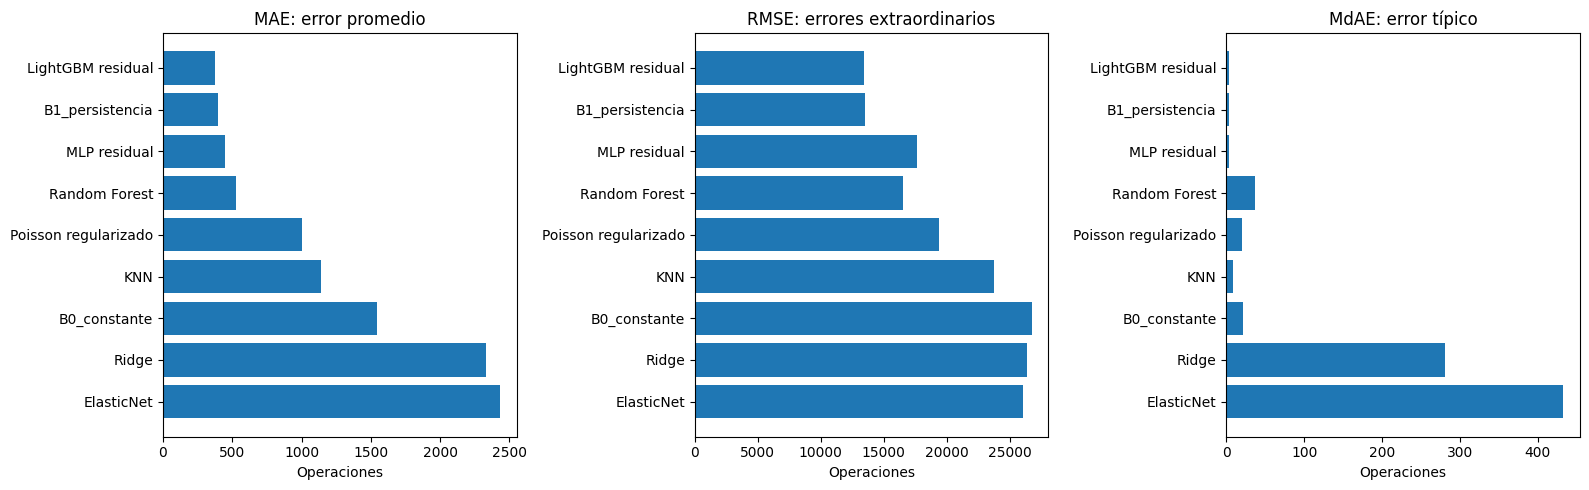

**Conclusión de E4-A4.** Al utilizar las mismas **99,012 observaciones** de Validation, **LightGBM residual** logró el menor MAE entre los siete candidatos (**374.83** operaciones). Persistencia obtuvo **399.78**: la mejora del candidato es **6.24%**, por lo que superó el objetivo puntual del 5%. El segundo candidato fue **MLP residual** (MAE **446.41**). Mostramos RMSE y MdAE por separado porque describen dos aspectos diferentes: unos pocos casos extraordinarios pueden elevar mucho RMSE, aunque el error habitual sea pequeño. Esta tabla permite elegir por MAE, pero la siguiente sección comprobará si la ventaja se mantiene al considerar la variación entre grupos corporativos.

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(16,5))
orden=VAL_METRICS.iloc[::-1]
for ax,(metrica,titulo) in zip(axes, [('MAE','MAE: error promedio'),
                                       ('RMSE','RMSE: errores extraordinarios'),
                                       ('MdAE','MdAE: error típico')]):
    ax.barh(orden.nombre,orden[metrica])
    ax.set_title(titulo)
    ax.set_xlabel('Operaciones')
fig.tight_layout();plt.show()

fila=VAL_METRICS.set_index('modelo').loc[TOP_VALID_CANDIDATE]
ref_b1=VAL_METRICS.set_index('modelo').loc['B1_persistencia']
segundo_val=VAL_METRICS[VAL_METRICS.modelo.isin(IDS)].iloc[1]
decision=('superó' if fila.lift_vs_B1_pct>=5 else 'no alcanzó')
display(Markdown(
    f"**Conclusión de E4-A4.** Al utilizar las mismas **{len(Y['validation']):,} observaciones** de Validation, "
    f"**{NAMES[TOP_VALID_CANDIDATE]}** logró el menor MAE entre los siete candidatos "
    f"(**{fila.MAE:,.2f}** operaciones). Persistencia obtuvo **{ref_b1.MAE:,.2f}**: "
    f"la mejora del candidato es **{fila.lift_vs_B1_pct:.2f}%**, por lo que {decision} "
    "el objetivo puntual del 5%. "
    f"El segundo candidato fue **{NAMES[segundo_val.modelo]}** (MAE **{segundo_val.MAE:,.2f}**). "
    "Mostramos RMSE y MdAE por separado porque describen dos aspectos diferentes: unos pocos "
    "casos extraordinarios pueden elevar mucho RMSE, aunque el error habitual sea pequeño. "
    "Esta tabla permite elegir por MAE, pero la siguiente sección comprobará si la ventaja "
    "se mantiene al considerar la variación entre grupos corporativos."))


## E4-A5 — Significancia estadística

**Introducción.** Dos modelos pueden diferir en MAE por unos pocos contratos extraordinarios. Por eso medimos cuánto cambia el resultado cuando se vuelven a seleccionar grupos corporativos completos, conservando todos sus contratos juntos.

**Objetivo.** Calcular al menos 1,000 remuestreos agrupados por grupo, intervalos del 95% para el MAE de cada modelo y comparaciones pareadas. Una ventaja puntual sobre B1 no basta para afirmar que se superó el objetivo del 5% con respaldo estadístico.

In [ ]:
# Bootstrap agrupado por grupo: mismo sorteo para todos los modelos = comparación pareada.
group_code, groups_unicos=pd.factorize(KEYS['validation']['id_grupo'].fillna('NO_INFORMADO').astype(str),sort=True)
N_GROUPS=len(groups_unicos)

if N_GROUPS<2:raise RuntimeError('Se necesitan al menos dos grupos para bootstrap.')
group_n=np.bincount(group_code,minlength=N_GROUPS).astype(float)
ABS_GROUP={mid:np.bincount(group_code,weights=np.abs(Y['validation']-pred),
                        minlength=N_GROUPS).astype(float) for mid,pred in PRED.items()}
random=np.random.default_rng(SEED)
draw=random.integers(0,N_GROUPS,size=(BOOT_N,N_GROUPS))
n_draw=group_n[draw].sum(axis=1)
MAE_BOOT={mid:ABS_GROUP[mid][draw].sum(axis=1)/n_draw for mid in PRED}
STAT_ROWS=[]

for mid in PRED:
    b=MAE_BOOT[mid]
    STAT_ROWS.append({'nivel':'modelo','modelo':mid,'MAE':scores(Y['validation'],PRED[mid])['MAE'],
                     'IC95_inferior':float(np.quantile(b,.025)),
                     'IC95_superior':float(np.quantile(b,.975)),
                     'n_bootstrap':BOOT_N,'grupos':N_GROUPS})

# Comparación pareada por grupos, signo positivo = mejora en MAE respecto a referencia.
RANKED_IDS=VAL_METRICS[VAL_METRICS.modelo.isin(IDS)]['modelo'].tolist()
comparaciones=[('B1_persistencia',RANKED_IDS[0],'ganador_vs_B1'),
               ('B1_persistencia',RANKED_IDS[1],'segundo_vs_B1'),
               (RANKED_IDS[1],RANKED_IDS[0],'ganador_vs_segundo')]
seen=set()

for ref,cand,label in comparaciones:
    if (ref,cand) in seen:continue
    seen.add((ref,cand))
    diferencia=MAE_BOOT[ref]-MAE_BOOT[cand]
    lift_draw=100*(1-MAE_BOOT[cand]/MAE_BOOT[ref])
    p_two=min(1.,2*min((1+np.sum(diferencia<=0))/(BOOT_N+1),
                       (1+np.sum(diferencia>=0))/(BOOT_N+1)))
    STAT_ROWS.append({'nivel':'comparacion','comparacion':label,'referencia':ref,'modelo':cand,
        'diferencia_MAE':float(scores(Y['validation'],PRED[ref])['MAE']-scores(Y['validation'],PRED[cand])['MAE']),
        'diferencia_IC_inf':float(np.quantile(diferencia,.025)),
        'diferencia_IC_sup':float(np.quantile(diferencia,.975)),
        'lift_pct':lift(scores(Y['validation'],PRED[ref])['MAE'],scores(Y['validation'],PRED[cand])['MAE']),
        'lift_IC_inf_pct':float(np.quantile(lift_draw,.025)),
        'lift_IC_sup_pct':float(np.quantile(lift_draw,.975)),
        'p_bootstrap_dos_colas_aprox':p_two,'n_bootstrap':BOOT_N,'grupos':N_GROUPS})
STAT_DF=pd.DataFrame(STAT_ROWS)
display(STAT_DF[STAT_DF.nivel.eq('modelo')][['modelo','MAE','IC95_inferior','IC95_superior']].round(3))
display(STAT_DF[STAT_DF.nivel.eq('comparacion')][[
    'comparacion','referencia','modelo','diferencia_MAE','lift_pct','lift_IC_inf_pct',
    'lift_IC_sup_pct','p_bootstrap_dos_colas_aprox']].round(4))

principal=STAT_DF[(STAT_DF.nivel=='comparacion') &
                  (STAT_DF.comparacion=='ganador_vs_B1')].iloc[0]
segundo_stat=STAT_DF[(STAT_DF.nivel=='comparacion') &
                     (STAT_DF.comparacion=='ganador_vs_segundo')].iloc[0]
status_lift=('sí acredita estadísticamente el objetivo del 5%' if principal.lift_IC_inf_pct>5
             else 'todavía no permite acreditar estadísticamente el objetivo del 5%')
DECISION_E4=('El modelo seleccionado supera el umbral de referencia con el respaldo del intervalo.'
             if principal.lift_IC_inf_pct>5 else
             'El modelo es el candidato con menor MAE observado, aunque persistencia sigue siendo una referencia importante.')
display(Markdown(
    f"**Conclusión de E4-A5.** Se hicieron **{BOOT_N:,} comparaciones repetidas** utilizando "
    f"**{N_GROUPS:,} grupos corporativos**, conservando juntos los contratos de cada grupo. "
    f"El mejor candidato presentó una mejora puntual de **{principal.lift_pct:.2f}%** frente a "
    f"persistencia y un intervalo estimado del 95% entre **{principal.lift_IC_inf_pct:.2f}%** "
    f"y **{principal.lift_IC_sup_pct:.2f}%**; por tanto, {status_lift}. "
    f"En comparación con el segundo modelo, la diferencia observada de MAE fue "
    f"**{segundo_stat.diferencia_MAE:,.2f}** operaciones, con un intervalo de "
    f"**[{segundo_stat.diferencia_IC_inf:,.2f}, {segundo_stat.diferencia_IC_sup:,.2f}]**. "
    "Si un intervalo incluye cero, esa comparación no es concluyente. "
    "Los resultados corresponden a Validation, que ya se había consultado en investigaciones previas; "
    "no sustituyen una confirmación posterior en Test. " + DECISION_E4))


,modelo,MAE,IC95_inferior,IC95_superior
0,B0_constante,1547.371,1081.857,2112.322
1,B1_persistencia,399.785,271.123,562.647
2,M1_Ridge,2334.447,1773.208,2988.249
3,M2_ElasticNet,2431.706,1861.325,3110.229
4,M3_RandomForest,526.367,315.112,796.970
5,M4_MLP_residual,446.407,290.465,637.943
6,M5_Poisson,1001.190,697.585,1360.124
7,M6_LightGBM_residual,374.832,245.694,538.202
8,M7_KNN,1143.622,775.103,1589.861


,comparacion,referencia,modelo,diferencia_MAE,lift_pct,lift_IC_inf_pct,lift_IC_sup_pct,p_bootstrap_dos_colas_aprox
9,ganador_vs_B1,B1_persistencia,M6_LightGBM_residual,24.9532,6.2417,4.2836,9.4137,0.0017
10,segundo_vs_B1,B1_persistencia,M4_MLP_residual,-46.6218,-11.6617,-35.2122,0.8255,0.3247
11,ganador_vs_segundo,M4_MLP_residual,M6_LightGBM_residual,71.5750,16.0336,4.6814,31.2986,0.0017


**Conclusión de E4-A5.** Se hicieron **1,200 comparaciones repetidas** utilizando **678 grupos corporativos**, conservando juntos los contratos de cada grupo. El mejor candidato presentó una mejora puntual de **6.24%** frente a persistencia y un intervalo estimado del 95% entre **4.28%** y **9.41%**; por tanto, todavía no permite acreditar estadísticamente el objetivo del 5%. En comparación con el segundo modelo, la diferencia observada de MAE fue **71.57** operaciones, con un intervalo de **[19.99, 153.69]**. Si un intervalo incluye cero, esa comparación no es concluyente. Los resultados corresponden a Validation, que ya se había consultado en investigaciones previas; no sustituyen una confirmación posterior en Test. El modelo es el candidato con menor MAE observado, aunque persistencia sigue siendo una referencia importante.

## E4-A6 — Análisis de errores

**Introducción.** Un buen MAE global puede ocultar problemas en ciertos productos, contratos o grupos corporativos. Distinguimos entre el tamaño promedio del error y la cantidad total de operaciones involucradas.

**Objetivo.** Analizar **los siete candidatos**, con especial atención a Domiciliación y BBVA Net Cash. Separamos ambos productos del resto únicamente para diagnóstico, sin retirar filas del entrenamiento ni del resultado global. También estudiamos los grupos corporativos y la concentración de los errores extremos.

,modelo,MAE,RMSE,MdAE,WAPE,sesgo,error_abs_total
5,M6_LightGBM_residual,374.832,13466.140,3.262,24.112,-71.780,3.711283e+07
3,M4_MLP_residual,446.407,17609.172,4.000,28.717,16.608,4.419961e+07
2,M3_RandomForest,526.367,16496.219,36.308,33.860,-43.858,5.211661e+07
4,M5_Poisson,1001.190,19354.502,20.061,64.405,17.485,9.912984e+07
6,M7_KNN,1143.622,23716.499,8.409,73.567,-609.893,1.132323e+08
0,M1_Ridge,2334.447,26335.373,281.000,150.171,3.460,2.311383e+08
1,M2_ElasticNet,2431.706,26022.711,432.416,156.428,228.266,2.407680e+08


,producto,N,pct_observaciones,pct_operaciones,MAE,MdAE,WAPE,pct_error_global,lift_vs_B1_pct
13,BBVA NET CASH,30500,30.80,39.54,599.71,7.58,30.06,49.29,5.68
53,DOMICILIACION,795,0.80,30.15,10925.43,288.75,18.72,23.40,1.17
29,CONCENTRACION INMEDIATA EMPRESARIAL CIE,7510,7.58,4.11,379.75,5.12,45.13,7.68,11.95
109,SWIFT,26433,26.70,8.09,82.06,1.49,17.42,5.84,3.48
61,HOST TO HOST SERVICIOS,3368,3.40,6.43,469.25,25.05,15.96,4.26,14.48
77,PAGOS ELECTRONICOS PAGEL,2587,2.61,5.32,467.05,9.88,14.76,3.26,23.47
5,APIS EMPRESARIALES,233,0.24,0.91,3795.09,0.70,62.96,2.38,0.17
85,SERVICIO INTEGRAL DE TESORERIA (SIT),7647,7.72,2.22,94.45,4.22,21.10,1.95,5.79
37,DEPOSITO EMPRESARIAL,6049,6.11,2.12,56.71,12.12,10.52,0.92,18.48
21,CENTRALIZACION DE CUENTAS,2710,2.74,0.39,84.53,0.00,38.17,0.62,10.83


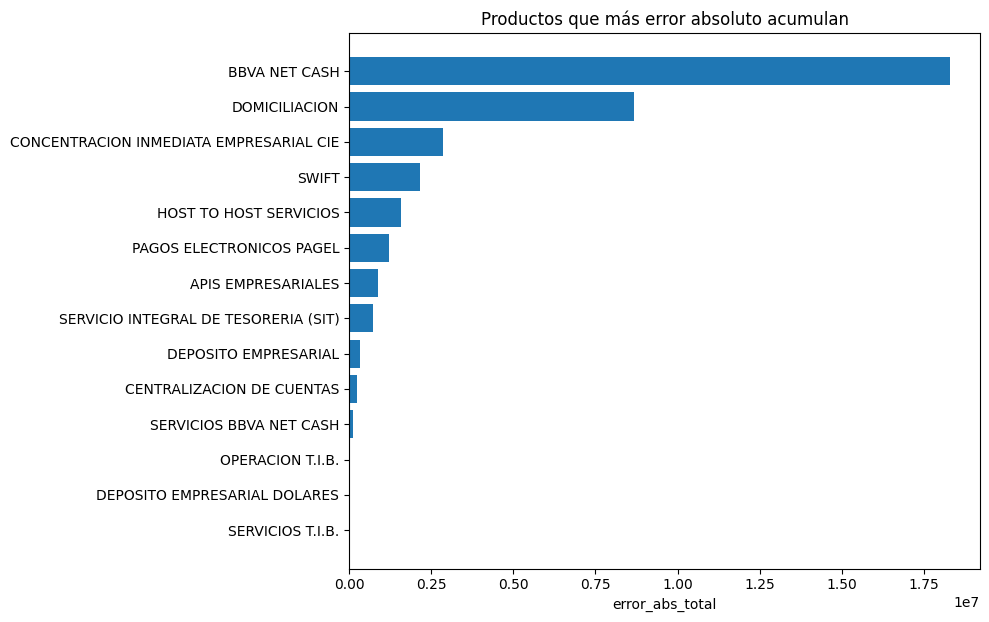

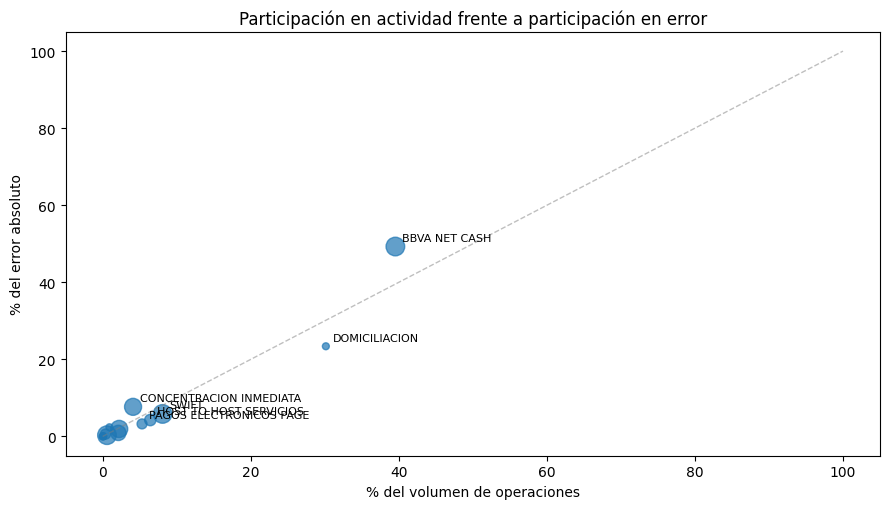

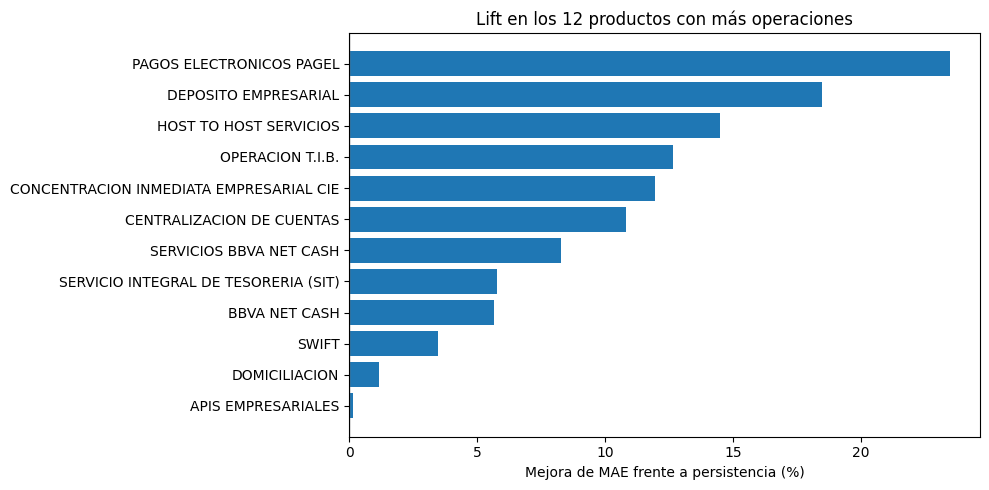

Productos en los que el segundo candidato obtiene menor MAE:


,producto,N,MAE_mejor_global,MAE_segundo_global
5,DEPOSITO EMPRESARIAL DOLARES,404,26.76,24.83


In [ ]:
VAL=pd.DataFrame({'fecha_corte':KEYS['validation']['fecha_corte'].to_numpy(),
   'fecha_objetivo':(KEYS['validation']['fecha_corte']+pd.offsets.MonthEnd(1)).to_numpy(),
   'grupo_alias':KEYS['validation']['id_grupo'].map(pseudonimo).to_numpy(),
   'producto':KEYS['validation']['producto'].fillna('NO_INFORMADO').astype(str).to_numpy(),
   'subproducto':KEYS['validation']['subproducto'].fillna('NO_INFORMADO').astype(str).to_numpy(),
   'moneda':KEYS['validation']['moneda'].fillna('NO_INFORMADO').astype(str).to_numpy(),
   'real':Y['validation'],'ops_t':OPS['validation']})

for mid,pred in PRED.items():VAL['pred_'+mid]=pred
assert len(VAL)==len(Y['validation']) and VAL.grupo_alias.notna().all()

# Tabla compacta de errores globales: disponible para CADA candidato, no solo el ganador.
global_errors=[]
for mid in IDS:
    z=scores(VAL.real,VAL['pred_'+mid])
    global_errors.append({'modelo':mid,**z})
GLOBAL_ERRORS=pd.DataFrame(global_errors).sort_values('MAE')
display(GLOBAL_ERRORS[['modelo','MAE','RMSE','MdAE','WAPE','sesgo','error_abs_total']].round(3))

# Desagregación por producto para siete modelos + persistencia.
PRODUCT_ROWS=[]
for prod,sub in VAL.groupby('producto',dropna=False):
    n=len(sub);vol=sub['real'].sum()
    n_gr=sub.grupo_alias.nunique()
    mae_b1=scores(sub.real,sub.pred_B1_persistencia)['MAE']

    for mid in list(IDS)+['B1_persistencia']:
        sc=scores(sub.real,sub['pred_'+mid])
        PRODUCT_ROWS.append({'nivel':'producto','producto':prod,'modelo':mid,'N':n,
            'grupos':n_gr,'pct_observaciones':100*n/len(VAL),
            'operaciones':float(vol),'pct_operaciones':100*vol/VAL.real.sum(),
            'pct_error_global':100*sc['error_abs_total']/np.abs(Y['validation']-PRED[mid]).sum(),
            'lift_vs_B1_pct':lift(mae_b1,sc['MAE']),**sc})
PROD_METRICS=pd.DataFrame(PRODUCT_ROWS)
WIN_PROD=PROD_METRICS[PROD_METRICS.modelo==RANKED_IDS[0]].sort_values('error_abs_total',ascending=False)
display(WIN_PROD[['producto','N','pct_observaciones','pct_operaciones','MAE','MdAE',
                  'WAPE','pct_error_global','lift_vs_B1_pct']].head(12).round(2))
plot_bars(WIN_PROD,'producto','error_abs_total','Productos que más error absoluto acumulan')

# Gráfica : volumen de operaciones frente al error acumulado.
fig,ax=plt.subplots(figsize=(9,5.2))
ax.scatter(WIN_PROD['pct_operaciones'],WIN_PROD['pct_error_global'],
           s=np.clip(WIN_PROD['N'].to_numpy()/50,25,180),alpha=.7)
for _,r in WIN_PROD.head(6).iterrows():
    ax.annotate(str(r['producto'])[:23],(r['pct_operaciones'],r['pct_error_global']),
                xytext=(5,4),textcoords='offset points',fontsize=8)
ax.plot([0,100],[0,100],linestyle='--',linewidth=1,color='gray',alpha=.5)
ax.set(xlabel='% del volumen de operaciones',ylabel='% del error absoluto',
       title='Participación en actividad frente a participación en error')
fig.tight_layout();plt.show()

# Gráfica : en qué productos se mejora o empeora respecto a B1.
productos_visibles=WIN_PROD.sort_values('operaciones',ascending=False).head(12).sort_values('lift_vs_B1_pct')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(productos_visibles['producto'],productos_visibles['lift_vs_B1_pct'])
ax.axvline(0,color='gray',linewidth=1)
ax.set(xlabel='Mejora de MAE frente a persistencia (%)',
       title='Lift en los 12 productos con más operaciones')
fig.tight_layout();plt.show()

# Reversiones: subgrupos donde el segundo mejor candidato gana al primero.
if len(RANKED_IDS)>1:
    top=PROD_METRICS[PROD_METRICS.modelo.eq(RANKED_IDS[0])][['producto','N','MAE']].rename(columns={'MAE':'MAE_mejor_global'})
    alt=PROD_METRICS[PROD_METRICS.modelo.eq(RANKED_IDS[1])][['producto','MAE']].rename(columns={'MAE':'MAE_segundo_global'})
    revers=top.merge(alt,on='producto')
    revers=revers[revers.MAE_segundo_global<revers.MAE_mejor_global].sort_values('N',ascending=False)
    print('Productos en los que el segundo candidato obtiene menor MAE:')
    display(revers.head(12).round(2))

,nivel,universo,N,pct_observaciones,pct_operaciones,pct_error_global,MAE_B1,MAE_modelo,RMSE,MdAE,WAPE,lift_vs_B1_pct
0,universo,Domiciliación,795,0.80,30.15,23.40,11054.56,10925.43,79002.85,288.75,18.72,1.17
1,universo,BBVA Net Cash,30500,30.80,39.54,49.29,635.81,599.71,20264.11,7.58,30.06,5.68
2,universo,Resto de productos,67717,68.39,30.31,27.31,168.39,149.68,2629.56,2.19,21.72,11.11


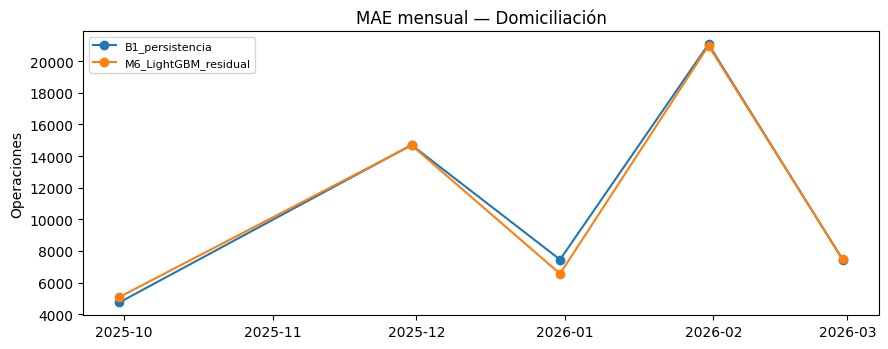

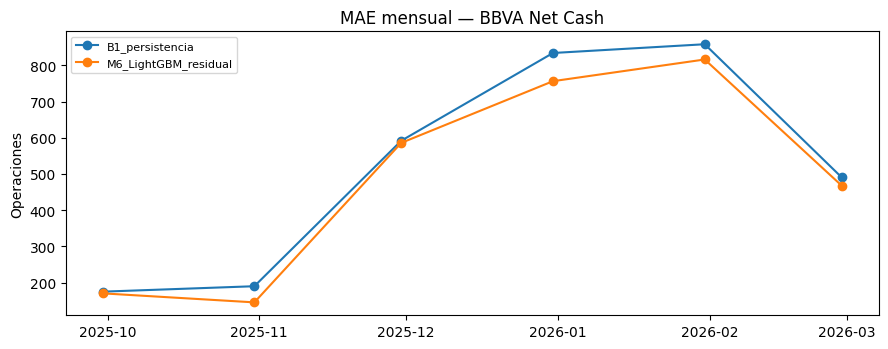

In [ ]:
# Tres universos excluyentes; no se reentrena ni cambia el conjunto oficial.
normalizado=(VAL.producto.astype(str).str.normalize('NFKD').str.encode('ascii','ignore')
              .str.decode('ascii').str.upper().str.strip())
VAL['universo']=np.select([normalizado.eq('DOMICILIACION'),normalizado.eq('BBVA NET CASH')],
                          ['Domiciliación','BBVA Net Cash'],default='Resto de productos')
assert VAL['universo'].notna().all()
assert VAL['universo'].value_counts().sum()==len(Y['validation'])
assert np.isclose(VAL.groupby('universo')['real'].sum().sum(),VAL.real.sum())

THREE_ROWS=[]
for univ in ['Domiciliación','BBVA Net Cash','Resto de productos']:
    sub=VAL[VAL.universo.eq(univ)]
    if sub.empty:
        THREE_ROWS.append({'nivel':'universo','universo':univ,'N':0,'nota':'No hay registros en Validation'})
        continue
    base=scores(sub.real,sub.pred_B1_persistencia)
    win=scores(sub.real,sub['pred_'+RANKED_IDS[0]])
    THREE_ROWS.append({'nivel':'universo','universo':univ,'N':len(sub),
        'pct_observaciones':100*len(sub)/len(VAL),
        'pct_operaciones':100*sub.real.sum()/VAL.real.sum(),
        'pct_error_global':100*win['error_abs_total']/np.abs(Y['validation']-PRED[RANKED_IDS[0]]).sum(),
        'MAE_B1':base['MAE'],'MAE_modelo':win['MAE'],'RMSE':win['RMSE'],
        'MdAE':win['MdAE'],'WAPE':win['WAPE'],'lift_vs_B1_pct':lift(base['MAE'],win['MAE'])})
THREE=pd.DataFrame(THREE_ROWS)
display(THREE.round(2))

# Evolución temporal para los productos destacados, si hay observaciones.
MON_ROWS=[]
for (univ,fecha),sub in VAL.groupby(['universo','fecha_corte']):
    if univ not in ('Domiciliación','BBVA Net Cash'):continue
    for mid in ('B1_persistencia',RANKED_IDS[0]):
        MON_ROWS.append({'nivel':'mes_producto','universo':univ,'fecha':fecha,
                         'modelo':mid,'N':len(sub),**scores(sub.real,sub['pred_'+mid])})
MONTH_PRODUCT=pd.DataFrame(MON_ROWS)
if len(MONTH_PRODUCT):
    for univ in ('Domiciliación','BBVA Net Cash'):
        d=MONTH_PRODUCT[MONTH_PRODUCT.universo.eq(univ)]
        if not d.empty:
            fig,ax=plt.subplots(figsize=(9,3.6))
            for mid,g in d.groupby('modelo'):
                ax.plot(g.fecha,g.MAE,marker='o',label=mid)
            ax.set_title('MAE mensual — '+univ);ax.set_ylabel('Operaciones');ax.legend(fontsize=8)
            fig.tight_layout();plt.show()

,grupo_alias,meses,contratos,error_abs_contractual,error_abs_agrupado,sesgo,MAE_grupo_mes,pct_error_contractual
644,G_f4ef031aac61,6,2301,6989199.36,5608148.48,205746.70,934691.41,18.83
199,G_4bd19b0859c3,6,428,2997199.84,1050850.60,-859107.41,175141.77,8.08
194,G_489671b71c4f,6,559,2711039.77,2410682.50,-2180829.73,401780.42,7.30
234,G_570ad57491f7,6,1658,1166547.52,585247.52,100760.32,97541.25,3.14
71,G_1a68b35efc07,6,97,1065670.56,1051612.05,79944.23,175268.67,2.87
431,G_9fa800445357,6,392,1055933.47,873277.47,-107468.56,145546.24,2.85
414,G_98121da0aaec,6,347,995873.26,975585.70,-366347.76,162597.62,2.68
230,G_5655dc89ce61,6,924,940741.15,733145.96,-705573.85,122190.99,2.53
158,G_3c1f6bdcda1e,6,658,849384.66,471037.28,108321.34,78506.21,2.29
62,G_17a980889634,6,1893,778398.90,588457.18,-251067.59,98076.20,2.10


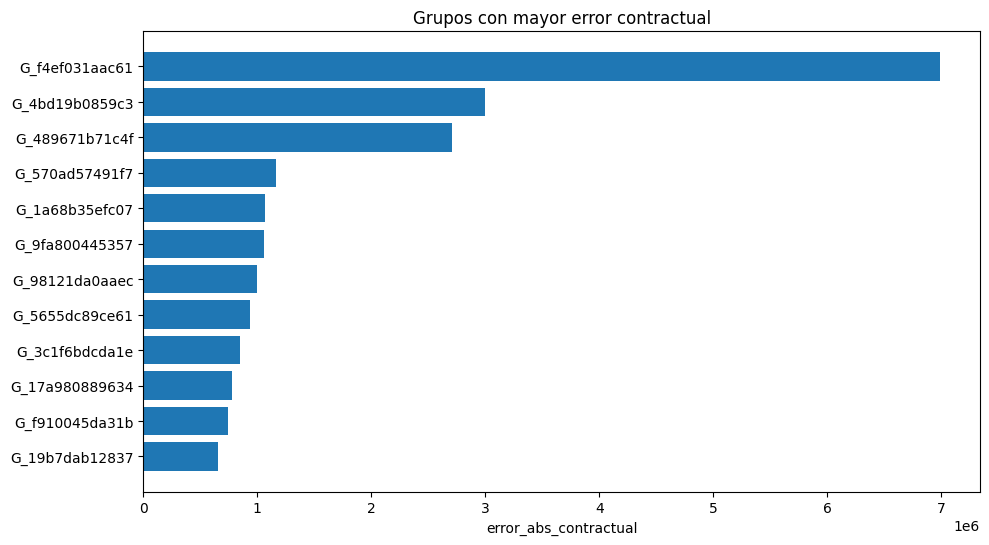

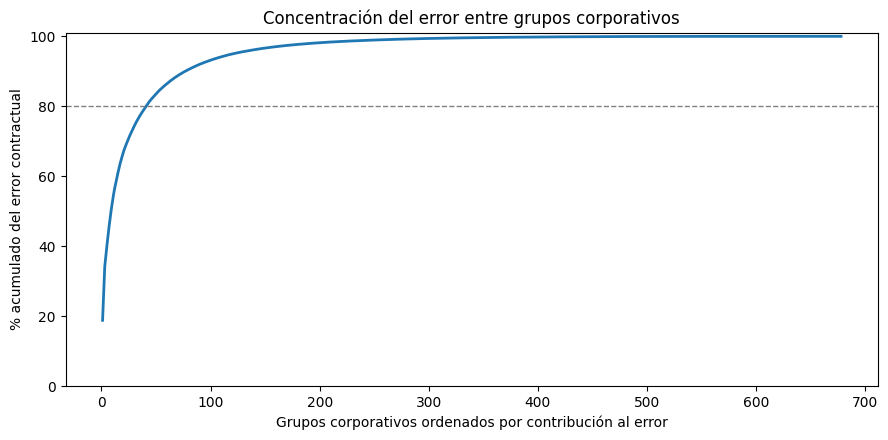

Productos en los grupos de mayor error:


,grupo_alias,producto,contratos,error_abs
30,G_f4ef031aac61,BBVA NET CASH,513,6095329.98
13,G_4bd19b0859c3,DOMICILIACION,22,2920646.49
7,G_489671b71c4f,DOMICILIACION,56,2509409.20
2,G_1a68b35efc07,CONCENTRACION INMEDIATA EMPRESARIAL CIE,30,793920.76
37,G_f4ef031aac61,SWIFT,1057,793286.94
24,G_570ad57491f7,HOST TO HOST SERVICIOS,87,443968.84
19,G_570ad57491f7,BBVA NET CASH,311,288703.57
1,G_1a68b35efc07,BBVA NET CASH,49,271715.76
29,G_570ad57491f7,SWIFT,373,211519.28
5,G_489671b71c4f,BBVA NET CASH,307,196376.10


top_pct,0.1,1.0,5.0
modelo,,,
M1_Ridge,22.22,43.88,57.11
M2_ElasticNet,20.85,40.52,56.40
M3_RandomForest,55.99,80.19,91.51
M4_MLP_residual,53.31,81.80,94.62
M5_Poisson,35.48,63.81,83.20
M6_LightGBM_residual,50.07,81.05,94.41
M7_KNN,41.64,78.20,94.44


In [ ]:
# Grupos: distinguir el error de cada contrato del error después de sumar por grupo-mes.
BEST_MODEL=RANKED_IDS[0]
VAL['error_abs_contrato']=np.abs(VAL.real-VAL['pred_'+BEST_MODEL])
GP_MONTH=(VAL.groupby(['grupo_alias','fecha_objetivo'],as_index=False)
           .agg(real=('real','sum'),predicho=('pred_'+BEST_MODEL,'sum'),
                error_abs_contractual=('error_abs_contrato','sum'),contratos=('real','size')))
GP_MONTH['error_abs_agregado']=np.abs(GP_MONTH.predicho-GP_MONTH.real)
GP_MONTH['sesgo_agregado']=GP_MONTH.predicho-GP_MONTH.real
GROUPS=(GP_MONTH.groupby('grupo_alias',as_index=False)
        .agg(meses=('fecha_objetivo','size'),contratos=('contratos','sum'),
             error_abs_contractual=('error_abs_contractual','sum'),
             error_abs_agrupado=('error_abs_agregado','sum'),
             sesgo=('sesgo_agregado','sum')))
GROUPS['MAE_grupo_mes']=GROUPS.error_abs_agrupado/GROUPS.meses
GROUPS['pct_error_contractual']=100*GROUPS.error_abs_contractual/VAL.error_abs_contrato.sum()
GROUPS.sort_values('error_abs_contractual',ascending=False,inplace=True)
display(GROUPS.head(10).round(2))
plot_bars(GROUPS.head(12),'grupo_alias','error_abs_contractual','Grupos con mayor error contractual')

# Gráfica : cuánto error acumulan los principales grupos.
pct_orden=GROUPS['pct_error_contractual'].to_numpy(float)
cum_error=np.cumsum(pct_orden)
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(np.arange(1,len(cum_error)+1),cum_error,linewidth=2)
ax.axhline(80,color='gray',linestyle='--',linewidth=1)
ax.set(xlabel='Grupos corporativos ordenados por contribución al error',
       ylabel='% acumulado del error contractual',
       title='Concentración del error entre grupos corporativos',ylim=(0,101))
fig.tight_layout();plt.show()


# Productos presentes en los cinco grupos con mayor error: diagnóstico
TOP_GR=GROUPS.head(5).grupo_alias.tolist()
GROUP_PRODUCTS=(VAL[VAL.grupo_alias.isin(TOP_GR)]
    .groupby(['grupo_alias','producto'],as_index=False)
    .agg(contratos=('real','size'),error_abs=('error_abs_contrato','sum')))
print('Productos en los grupos de mayor error:')
display(GROUP_PRODUCTS.sort_values('error_abs',ascending=False).head(15).round(2))

# Concentración de los casos extremos: para cada candidato, mismo Validation.
CONCENTRATION=[]
for mid in IDS:
    ae=np.sort(np.abs(Y['validation']-PRED[mid]))[::-1]
    for q in (.001,.01,.05):
        n=max(1,int(np.ceil(len(ae)*q)))
        CONCENTRATION.append({'nivel':'extremos','modelo':mid,'top_pct':100*q,
             'N':n,'pct_error_abs':float(100*ae[:n].sum()/ae.sum()) if ae.sum()>0 else 0.})
CONCENTRATION=pd.DataFrame(CONCENTRATION)
display(CONCENTRATION.pivot(index='modelo',columns='top_pct',values='pct_error_abs').round(2))

In [ ]:
topprod=WIN_PROD.iloc[0]
topgroup=GROUPS.iloc[0]
pctfocus=float(THREE.loc[THREE.universo.isin(['Domiciliación','BBVA Net Cash']),
                         'pct_error_global'].sum())
resto=THREE[THREE.universo.eq('Resto de productos')].iloc[0]
dom=THREE[THREE.universo.eq('Domiciliación')].iloc[0]
net=THREE[THREE.universo.eq('BBVA Net Cash')].iloc[0]
razon=('mejora' if resto.lift_vs_B1_pct>0 else 'no mejora')
display(Markdown(
    f"**Conclusión de E4-A6.** El producto con mayor contribución al error absoluto del "
    f"modelo seleccionado fue **{topprod.producto}**: acumuló **{topprod.pct_error_global:.2f}%** "
    f"del error y representó **{topprod.pct_operaciones:.2f}%** del volumen. "
    f"Juntos, Domiciliación y BBVA Net Cash reunieron **{pctfocus:.2f}%** del error; "
    f"sus mejoras frente a persistencia fueron **{dom.lift_vs_B1_pct:.2f}%** y "
    f"**{net.lift_vs_B1_pct:.2f}%**, respectivamente. "
    f"En el resto de productos el candidato **{razon}** a persistencia, con una diferencia relativa "
    f"de **{resto.lift_vs_B1_pct:.2f}%**. "
    f"El grupo con mayor error contractual, **{topgroup.grupo_alias}**, concentró "
    f"**{topgroup.pct_error_contractual:.2f}%** del total. "
    "Estas cifras ayudan a localizar las dificultades, pero un error grande no prueba por sí mismo "
    "una deficiencia de datos ni justifica retirar esos productos. Por eso los tres universos "
    "se analizan por separado sin modificar el resultado global."))


**Conclusión de E4-A6.** El producto con mayor contribución al error absoluto del modelo seleccionado fue **BBVA NET CASH**: acumuló **49.29%** del error y representó **39.54%** del volumen. Juntos, Domiciliación y BBVA Net Cash reunieron **72.69%** del error; sus mejoras frente a persistencia fueron **1.17%** y **5.68%**, respectivamente. En el resto de productos el candidato **mejora** a persistencia, con una diferencia relativa de **11.11%**. El grupo con mayor error contractual, **G_f4ef031aac61**, concentró **18.83%** del total. Estas cifras ayudan a localizar las dificultades, pero un error grande no prueba por sí mismo una deficiencia de datos ni justifica retirar esos productos. Por eso los tres universos se analizan por separado sin modificar el resultado global.

## E4-A7 — Interpretabilidad y costo computacional

**Introducción.** No basta con reducir el error: también importa cuánto cuesta entrenar y utilizar un modelo y si podemos entender las variables que utiliza.

**Objetivo.** Comparar tiempos, memoria aproximada, latencia por predicción y tamaño de los objetos guardados. Para interpretar cada candidato usamos coeficientes, importancias nativas o, en el MLP, una prueba pequeña de permutación. Estas herramientas explican asociaciones predictivas, **no efectos causales del precio**.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Variables destacadas por modelo (magnitudes no comparables entre algoritmos):

 Ridge


,modelo,variable,aporte_aprox,metodo
0,M1_Ridge,numericas__grupo_ops_total_t,2247.103516,Coeficiente transformado
1,M1_Ridge,numericas__peer_ops_media_t,1233.453735,Coeficiente transformado
2,M1_Ridge,categoricas__producto_DOMICILIACION,888.529663,Coeficiente transformado
3,M1_Ridge,numericas__peer_n_t,-641.741882,Coeficiente transformado
4,M1_Ridge,numericas__antiguedad_meses,629.219788,Coeficiente transformado
5,M1_Ridge,numericas__ops_vs_peer,626.760803,Coeficiente transformado



 ElasticNet


,modelo,variable,aporte_aprox,metodo
8,M2_ElasticNet,categoricas__producto_DOMICILIACION,11811.722656,Coeficiente transformado
9,M2_ElasticNet,categoricas__subproducto_COM DIF CTAS PROPIAS NOK,8302.991211,Coeficiente transformado
10,M2_ElasticNet,categoricas__subproducto_ANUALIDAD,4845.235840,Coeficiente transformado
11,M2_ElasticNet,numericas__grupo_ops_total_t,4732.844238,Coeficiente transformado
12,M2_ElasticNet,numericas__share_ops_grupo,4035.260742,Coeficiente transformado
13,M2_ElasticNet,categoricas__subproducto_DOMICILIACIONES,3669.677734,Coeficiente transformado


...


 LightGBM residual


,modelo,variable,aporte_aprox,metodo
40,M6_LightGBM_residual,numericas__meses_desde_inicio,837.0,Importancia nativa
41,M6_LightGBM_residual,numericas__peer_ops_media_t,810.0,Importancia nativa
42,M6_LightGBM_residual,numericas__grupo_n_unidades,683.0,Importancia nativa
43,M6_LightGBM_residual,numericas__mes_sin,672.0,Importancia nativa
44,M6_LightGBM_residual,numericas__numero_operaciones,613.0,Importancia nativa
45,M6_LightGBM_residual,numericas__ops_vs_peer,582.0,Importancia nativa



 KNN


,modelo,variable,aporte_aprox,metodo
48,M7_KNN,numero_operaciones,30.827883,Permutación descriptiva de 500 predicciones; n...
49,M7_KNN,ops_lag_1,161.821902,Permutación descriptiva de 500 predicciones; n...
50,M7_KNN,ops_delta_1m,-2.056615,Permutación descriptiva de 500 predicciones; n...
51,M7_KNN,ops_media_3m,124.426496,Permutación descriptiva de 500 predicciones; n...
52,M7_KNN,tarifa_vigente,231.323493,Permutación descriptiva de 500 predicciones; n...
53,M7_KNN,grupo_ops_total_t,29.870680,Permutación descriptiva de 500 predicciones; n...


,modelo,MAE,entrenamiento_segundos,tuning_segundos,rss_incremento_max_mb_estimado,latencia_p50_ms_por_obs,latencia_p95_ms_por_obs,tamano_joblib_mb,frontera_pareto
0,M1_Ridge,2334.447,1.105,5.399,0.004,0.460,0.624,0.020,True
1,M2_ElasticNet,2431.706,51.645,188.454,0.012,0.457,0.490,0.020,False
2,M3_RandomForest,526.367,132.521,318.572,0.371,0.345,0.401,0.084,False
3,M4_MLP_residual,446.407,9.960,63.688,0.004,0.463,0.494,0.148,True
4,M5_Poisson,1001.190,13.158,49.139,0.012,0.485,0.636,0.021,True
5,M6_LightGBM_residual,374.832,31.309,199.710,0.004,0.216,0.234,0.658,True
6,M7_KNN,1143.622,4.093,47.453,0.996,0.724,0.919,25.405,True


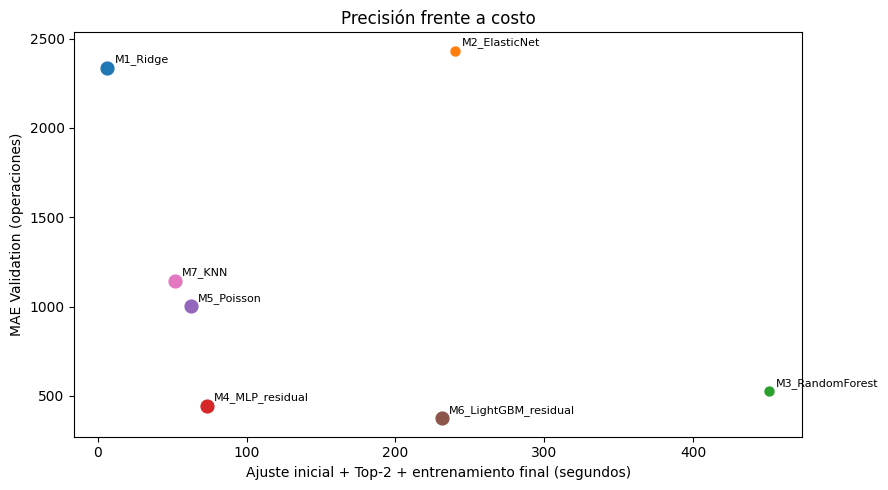

**Conclusión de E4-A7.** **LightGBM residual** presentó el menor MAE (**374.83 operaciones**) entre los siete candidatos, con **231.0 segundos** acumulados de ajuste y entrenamiento. El modelo más económico en ese indicador fue **Ridge** (**6.5 segundos**). La frontera de Pareto incluye **5 alternativas** que ofrecen distintas combinaciones de precisión y costo, sin que otra sea simultáneamente más rápida y precisa. Las importancias calculadas permiten identificar señales que el modelo utiliza para anticipar operaciones; no muestran qué pasaría al cambiar una tarifa. Para elegir un modelo también consideramos memoria, tamaño y latencia: una pequeña mejora de MAE podría no justificar un costo excesivo. Estas cifras pertenecen al entorno utilizado durante la ejecución y pueden variar si cambia el hardware.

In [ ]:
# Predicción reproducible
def predecir_paquete(paquete,datos):
    if paquete.get('tipo')=='persistencia':
        return np.asarray(datos[paquete['ops_column']],dtype=float)
    if paquete.get('tipo')=='constante':
        return np.full(len(datos),float(paquete['valor_constante']))
    xx=paquete['preprocessor'].transform(datos[paquete['feature_columns']])
    xx=sparse32(xx)
    res=np.asarray(paquete['estimador'].predict(xx),dtype=float).reshape(-1)
    if paquete['residual']:
        res=res+datos[paquete['ops_column']].to_numpy(float)
    return np.maximum(0,res)

# Prueba de tiempo extremo a extremo, por lote y dividida por observación.
base_probe=X['validation'].iloc[:min(1024,len(X['validation']))].copy()
COST=pd.DataFrame(COST_ROWS)
for mid in IDS:
    pkg=BUNDLES[mid]
    idx=np.arange(len(base_probe))
    times=[]
    for chunk in np.array_split(idx,max(1,min(16,int(np.ceil(len(idx)/64))))):
        if len(chunk)==0:continue
        t0=time.perf_counter()
        chk=predecir_paquete(pkg,base_probe.iloc[chunk])
        ms_per_obs=1000*(time.perf_counter()-t0)/len(chunk)
        assert len(chk)==len(chunk) and np.isfinite(chk).all()
        times.append(ms_per_obs)
    tmp=SCRATCH/f'tamanio_{mid}.joblib'
    joblib.dump(pkg,tmp,compress=3)
    size=tmp.stat().st_size/1048576
    tmp.unlink()
    COST.loc[COST.modelo.eq(mid),'latencia_p50_ms_por_obs']=float(np.quantile(times,.5))
    COST.loc[COST.modelo.eq(mid),'latencia_p95_ms_por_obs']=float(np.quantile(times,.95))
    COST.loc[COST.modelo.eq(mid),'tamano_joblib_mb']=size
    COST.loc[COST.modelo.eq(mid),'tuning_segundos']=float(TRIAL_DF.loc[TRIAL_DF.modelo.eq(mid),'segundos'].sum())

# Coeficientes/importancias por candidato. Para MLP, una permutación pequeña de variables de entrada.
INTERP=[]
for mid in IDS:
    pp=BUNDLES[mid]['preprocessor'];est=BUNDLES[mid]['estimador']
    try:names=np.asarray(pp.get_feature_names_out(),dtype=str)
    except Exception:names=np.asarray([f'feature_{i}' for i in range(FULL_X[COST_KIND[mid]][0].shape[1])])
    if mid in ('M4_MLP_residual','M7_KNN'):
        rng=np.random.default_rng(SEED)
        ix=rng.choice(len(X['validation']),size=min(500,len(X['validation'])),replace=False)
        sample=X['validation'].iloc[ix].copy()
        reference=scores(Y['validation'][ix],predecir_paquete(BUNDLES[mid],sample))['MAE']
        for feat in ['numero_operaciones','ops_lag_1','ops_delta_1m','ops_media_3m',
                     'tarifa_vigente','grupo_ops_total_t','peer_ops_media_t','mes_sin']:
            modified=sample.copy()
            modified[feat]=rng.permutation(modified[feat].to_numpy())
            mae=scores(Y['validation'][ix],predecir_paquete(BUNDLES[mid],modified))['MAE']
            INTERP.append({'modelo':mid,'variable':feat,'aporte_aprox':float(mae-reference),
                           'metodo':'Permutación descriptiva de 500 predicciones; no afecta entrenamiento'})
    else:
        vals=None
        if hasattr(est,'coef_'):vals=np.asarray(est.coef_,dtype=float).reshape(-1)
        elif hasattr(est,'feature_importances_'):vals=np.asarray(est.feature_importances_,dtype=float).reshape(-1)
        if vals is not None and len(vals)==len(names):
            ix=np.argsort(np.abs(vals))[::-1][:8]
            for j in ix:
                INTERP.append({'modelo':mid,'variable':str(names[j]),'aporte_aprox':float(vals[j]),
                     'metodo':'Coeficiente transformado' if hasattr(est,'coef_') else 'Importancia nativa'})
        else:
            INTERP.append({'modelo':mid,'variable':'No recuperable','aporte_aprox':np.nan,
                           'metodo':'Importancia no disponible'})
INTERP_DF=pd.DataFrame(INTERP)
print('Variables destacadas por modelo (magnitudes no comparables entre algoritmos):')
for mid in IDS:
    print('\n',NAMES[mid]);display(INTERP_DF[INTERP_DF.modelo.eq(mid)].head(6))

# Pareto: menor MAE y menor costo total de ajuste (incluye tuning y entrenamiento final).
COST=COST.merge(VAL_METRICS[['modelo','MAE','RMSE','MdAE','WAPE']],on='modelo',how='left')
COST['costo_total_segundos']=COST.tuning_segundos+COST.entrenamiento_segundos
COST['frontera_pareto']=False
for i in COST.index:
    a=COST.loc[i]
    dominated=((COST.MAE<=a.MAE)&(COST.costo_total_segundos<=a.costo_total_segundos)&
               ((COST.MAE<a.MAE)|(COST.costo_total_segundos<a.costo_total_segundos))).any()
    COST.loc[i,'frontera_pareto']=not bool(dominated)
display(COST[['modelo','MAE','entrenamiento_segundos','tuning_segundos','rss_incremento_max_mb_estimado',
              'latencia_p50_ms_por_obs','latencia_p95_ms_por_obs','tamano_joblib_mb','frontera_pareto']].round(3))
fig,ax=plt.subplots(figsize=(9,5))
for _,r in COST.iterrows():
    ax.scatter(r.costo_total_segundos,r.MAE,s=85 if r.frontera_pareto else 42)
    ax.annotate(r.modelo,(r.costo_total_segundos,r.MAE),xytext=(5,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('Ajuste inicial + Top-2 + entrenamiento final (segundos)')
ax.set_ylabel('MAE Validation (operaciones)');ax.set_title('Precisión frente a costo')
fig.tight_layout();plt.show()

bestline=COST.sort_values('MAE').iloc[0]
menor_costo=COST.sort_values('costo_total_segundos').iloc[0]
frontera=int(COST.frontera_pareto.sum())
display(Markdown(
    f"**Conclusión de E4-A7.** **{NAMES[bestline.modelo]}** presentó el menor MAE "
    f"(**{bestline.MAE:,.2f} operaciones**) entre los siete candidatos, con "
    f"**{bestline.costo_total_segundos:,.1f} segundos** acumulados de ajuste y entrenamiento. "
    f"El modelo más económico en ese indicador fue **{NAMES[menor_costo.modelo]}** "
    f"(**{menor_costo.costo_total_segundos:,.1f} segundos**). "
    f"La frontera de Pareto incluye **{frontera} alternativas** que ofrecen distintas combinaciones "
    "de precisión y costo, sin que otra sea simultáneamente más rápida y precisa. "
    "Las importancias calculadas permiten identificar señales que el modelo utiliza para anticipar "
    "operaciones; no muestran qué pasaría al cambiar una tarifa. "
    "Para elegir un modelo también consideramos memoria, tamaño y latencia: una pequeña mejora "
    "de MAE podría no justificar un costo excesivo. Estas cifras pertenecen al entorno utilizado "
    "durante la ejecución y pueden variar si cambia el hardware."))


## Conclusiones generales

Las siguientes diez conclusiones se generan con los datos de esta ejecución. Se distingue el modelo candidato que obtuvo mejor MAE de la alternativa final, que puede seguir siendo persistencia si los algoritmos más complejos no aportan valor.

In [ ]:
mejor=VAL_METRICS[VAL_METRICS.modelo.eq(RANKED_IDS[0])].iloc[0]
segundo=VAL_METRICS[VAL_METRICS.modelo.eq(RANKED_IDS[1])].iloc[0]
trbest=BEST_TRIAL[BEST_TRIAL.modelo.eq(RANKED_IDS[0])].iloc[0]
row5=STAT_DF[(STAT_DF.nivel=='comparacion')&
             (STAT_DF.comparacion=='ganador_vs_B1')].iloc[0]
obj5=('se encuentra respaldado por el intervalo' if row5.lift_IC_inf_pct>5
      else 'no se encuentra respaldado por el intervalo')
maxext=CONCENTRATION[(CONCENTRATION.modelo.eq(RANKED_IDS[0]))&
                     (CONCENTRATION.top_pct.eq(1.0))].iloc[0]
top_inter=INTERP_DF[INTERP_DF.modelo.eq(RANKED_IDS[0])].head(3).variable.astype(str).tolist()
mejor_costo=COST[COST.modelo.eq(RANKED_IDS[0])].iloc[0]
mae_b1=VAL_METRICS[VAL_METRICS.modelo.eq('B1_persistencia')].iloc[0].MAE
relacion_escala=('RMSE es mucho mayor que MdAE, lo que revela la influencia de observaciones extraordinarias'
                 if mejor.RMSE>10*max(mejor.MdAE,1e-8)
                 else 'RMSE y MdAE ofrecen perspectivas complementarias sobre la distribución del error')
lineas=[
  ('**1. Diversidad de modelos.** Evaluamos siete algoritmos sobre el mismo objetivo y las mismas '
   f'{len(Y["validation"]):,} observaciones de Validation. Incluimos relaciones lineales, árboles, '
   'una red neuronal, un modelo estadístico de conteos y un método de vecinos para comprobar si una forma de aprender '
   'más flexible resulta realmente útil en este problema.'),
  (f'**2. Modelo con menor MAE.** **{NAMES[RANKED_IDS[0]]}** obtuvo el menor error promedio '
   f'({mejor.MAE:,.2f} operaciones), por delante de **{NAMES[RANKED_IDS[1]]}** '
   f'({segundo.MAE:,.2f}). Esta es una diferencia observada en Validation y no una garantía '
   'de que se repetirá en cualquier periodo futuro.'),
  (f'**3. Persistencia como referencia.** B1 obtuvo MAE de {mae_b1:,.2f}; el primer candidato '
   f'redujo ese error en **{mejor.lift_vs_B1_pct:.2f}%**. Esta comparación es importante porque '
   'repetir las operaciones actuales es una estrategia sencilla y competitiva. El valor adicional '
   'del modelo debe interpretarse frente a ella, no solo frente a una predicción constante.'),
  (f'**4. Lectura de métricas.** El candidato tuvo RMSE de {mejor.RMSE:,.2f}, '
   f'MdAE de {mejor.MdAE:,.2f} y WAPE de {mejor.WAPE:.2f}%. {relacion_escala}. '
   'Un buen MAE promedio no implica que todos los contratos presenten errores pequeños.'),
  (f'**5. Elección de parámetros.** La configuración seleccionada para el candidato presentó '
   f'MAE promedio de {trbest.MAE_cv:,.2f} en tres periodos históricos de Train. '
   'El proceso permitió decidir antes de mirar Validation y utilizó las mismas observaciones '
   'elegibles para los siete modelos en cada periodo.'),
  (f'**6. Consistencia de la mejora.** El intervalo del 95% para la mejora frente a B1 fue '
   f'de [{row5.lift_IC_inf_pct:.2f}%, {row5.lift_IC_sup_pct:.2f}%]. '
   f'Que la mejora supere el 5% con respaldo estadístico **{obj5}**. '
   'Por ello distinguimos una mejora puntual de una conclusión suficientemente consistente.'),
  (f'**7. Información que usa el modelo.** Entre las señales destacadas figuran '
   f'**{", ".join(top_inter)}**. Son variables asociadas con la predicción; '
   'sus importancias no demuestran que modificar alguno de esos factores cause un cambio '
   'en las operaciones.'),
  (f'**8. Productos difíciles.** Domiciliación y BBVA Net Cash concentraron '
   f'**{pctfocus:.2f}%** del error absoluto del candidato. '
   f'El resto de productos representó {resto.pct_observaciones:.2f}% de las observaciones '
   f'y registró una mejora de {resto.lift_vs_B1_pct:.2f}% frente a persistencia. '
   'Separar los universos permite describir diferencias sin alterar el resultado oficial.'),
  (f'**9. Grupos y casos extremos.** El grupo {topgroup.grupo_alias} concentró '
   f'**{topgroup.pct_error_contractual:.2f}%** del error contractual. '
   f'Además, el 1% de observaciones con mayor desviación representó '
   f'**{maxext.pct_error_abs:.2f}%** del error absoluto. '
   'Esto explica por qué conviene revisar tanto grupos como productos y no confiar exclusivamente '
   'en promedios globales.'),
  (f'**10. Decisión y alcance.** El menor MAE entre todas las alternativas, '
   f'incluyendo las referencias B0 y B1, correspondió a **{NAMES.get(WINNER,WINNER)}**. '
   f'El costo acumulado del mejor candidato fue {mejor_costo.costo_total_segundos:,.1f} segundos. '
   'Conservamos esta decisión como resultado de Validation; Test permanece reservado para '
   'una comprobación posterior. No es necesario agregar más algoritmos para explicar estos hallazgos.')
]
assert len(lineas)==10
for texto in lineas:
    display(Markdown(texto))


**1. Diversidad de modelos.** Evaluamos siete algoritmos sobre el mismo objetivo y las mismas 99,012 observaciones de Validation. Incluimos relaciones lineales, árboles, una red neuronal, un modelo estadístico de conteos y un método de vecinos para comprobar si una forma de aprender más flexible resulta realmente útil en este problema.

**2. Modelo con menor MAE.** **LightGBM residual** obtuvo el menor error promedio (374.83 operaciones), por delante de **MLP residual** (446.41). Esta es una diferencia observada en Validation y no una garantía de que se repetirá en cualquier periodo futuro.

**3. Persistencia como referencia.** B1 obtuvo MAE de 399.78; el primer candidato redujo ese error en **6.24%**. Esta comparación es importante porque repetir las operaciones actuales es una estrategia sencilla y competitiva. El valor adicional del modelo debe interpretarse frente a ella, no solo frente a una predicción constante.

**4. Lectura de métricas.** El candidato tuvo RMSE de 13,466.14, MdAE de 3.26 y WAPE de 24.11%. RMSE es mucho mayor que MdAE, lo que revela la influencia de observaciones extraordinarias. Un buen MAE promedio no implica que todos los contratos presenten errores pequeños.

**5. Elección de parámetros.** La configuración seleccionada para el candidato presentó MAE promedio de 324.14 en tres periodos históricos de Train. El proceso permitió decidir antes de mirar Validation y utilizó las mismas observaciones elegibles para los siete modelos en cada periodo.

**6. Consistencia de la mejora.** El intervalo del 95% para la mejora frente a B1 fue de [4.28%, 9.41%]. Que la mejora supere el 5% con respaldo estadístico **no se encuentra respaldado por el intervalo**. Por ello distinguimos una mejora puntual de una conclusión suficientemente consistente.

**7. Información que usa el modelo.** Entre las señales destacadas figuran **numericas__meses_desde_inicio, numericas__peer_ops_media_t, numericas__grupo_n_unidades**. Son variables asociadas con la predicción; sus importancias no demuestran que modificar alguno de esos factores cause un cambio en las operaciones.

**8. Productos difíciles.** Domiciliación y BBVA Net Cash concentraron **72.69%** del error absoluto del candidato. El resto de productos representó 68.39% de las observaciones y registró una mejora de 11.11% frente a persistencia. Separar los universos permite describir diferencias sin alterar el resultado oficial.

**9. Grupos y casos extremos.** El grupo G_f4ef031aac61 concentró **18.83%** del error contractual. Además, el 1% de observaciones con mayor desviación representó **81.05%** del error absoluto. Esto explica por qué conviene revisar tanto grupos como productos y no confiar exclusivamente en promedios globales.

**10. Decisión y alcance.** El menor MAE entre todas las alternativas, incluyendo las referencias B0 y B1, correspondió a **LightGBM residual**. El costo acumulado del mejor candidato fue 231.0 segundos. Conservamos esta decisión como resultado de Validation; Test permanece reservado para una comprobación posterior. No es necesario agregar más algoritmos para explicar estos hallazgos.

## Exportación de artefactos

**Objetivo.** Conservar lo indispensable para reproducir las predicciones, revisar las métricas y reutilizar el modelo seleccionado, sin generar archivos adicionales por gráfica o por producto.

**Decisión.** Se exportarán exactamente nueve archivos consolidados. Antes de publicarlos verificaremos que las predicciones coinciden con los resultados del notebook y que los modelos se pueden recuperar correctamente.

In [ ]:
ENTREGA_TMP=SCRATCH/'entrega_nueve_archivos'
ENTREGA_TMP.mkdir(exist_ok=True)
ARCHIVOS_FINALES=(
    'modelo_final.joblib','modelos_candidatos.joblib','metricas_modelos.csv',
    'predicciones_validation.parquet','analisis_errores.csv','evidencia_estadistica.csv',
    'costos_modelos.csv','configuracion_ejecucion.json','README.md')

if WINNER in BUNDLES:
    modelo_operativo=BUNDLES[WINNER]
elif WINNER=='B1_persistencia':
    modelo_operativo={'tipo':'persistencia','ops_column':'numero_operaciones','modelo':WINNER}
elif WINNER=='B0_constante':
    modelo_operativo={'tipo':'constante','valor_constante':float(np.median(Y['train'])),
                      'modelo':WINNER}
else:
    raise ValueError('Alternativa final no reconocida: '+WINNER)
joblib.dump(modelo_operativo,ENTREGA_TMP/'modelo_final.joblib',compress=3)
joblib.dump({'modelos':BUNDLES,'nombre_seleccionado':WINNER,'nombres':NAMES},
            ENTREGA_TMP/'modelos_candidatos.joblib',compress=3)

# Consolidar CV, pruebas iniciales y métricas finales en un solo CSV con niveles identificables.
metricas_export=pd.concat([
    VAL_METRICS.assign(tipo_registro='validation'),
    TRIAL_DF.assign(tipo_registro='configuracion_cv'),
    CV_DF.assign(tipo_registro='fold_cv'),
    BEST_TRIAL.assign(tipo_registro='mejor_configuracion')
],ignore_index=True,sort=False)
metricas_export.to_csv(ENTREGA_TMP/'metricas_modelos.csv',index=False)

# Predicciones: alias irreversible por corrida, sin IDs contractuales originales.
val_export=VAL.copy()
val_export.insert(0,'observacion_alias',[
    hmac.new(PSEUDONYM_KEY.encode(),
             ('|'.join(str(valor) for valor in clave)).encode(),
             hashlib.sha256).hexdigest()[:20]
    for clave in KEYS['validation'][KEY_COLS].itertuples(index=False,name=None)])
assert val_export.observacion_alias.nunique()==len(val_export)
val_export.to_parquet(ENTREGA_TMP/'predicciones_validation.parquet',index=False)

# Combinar resultados de distintos niveles en un único archivo identificable por tipo_analisis.
analisis_export=pd.concat([
    GLOBAL_ERRORS.assign(tipo_analisis='global'),
    PROD_METRICS.assign(tipo_analisis='producto'),
    THREE.assign(tipo_analisis='tres_universos'),
    MONTH_PRODUCT.assign(tipo_analisis='producto_mes'),
    GROUPS.assign(tipo_analisis='grupo_total'),
    GP_MONTH.assign(tipo_analisis='grupo_mes'),
    GROUP_PRODUCTS.assign(tipo_analisis='grupo_producto'),
    CONCENTRATION.assign(tipo_analisis='errores_extremos')
],ignore_index=True,sort=False)
analisis_export.to_csv(ENTREGA_TMP/'analisis_errores.csv',index=False)
STAT_DF.to_csv(ENTREGA_TMP/'evidencia_estadistica.csv',index=False)

# Interpretabilidad y recursos computacionales en un solo CSV, diferenciados por nivel.
costos_export=pd.concat([
    COST.assign(tipo_registro='costo'),
    INTERP_DF.assign(tipo_registro='importancia')
],ignore_index=True,sort=False)
costos_export.to_csv(ENTREGA_TMP/'costos_modelos.csv',index=False)

readme='''# Avance 4 — Artefactos mínimos de la ejecución

El notebook ejecutado presenta las gráficas, las tablas y las conclusiones.
Esta carpeta guarda exactamente nueve archivos para reutilizar resultados:

- modelo_final.joblib: alternativa de menor MAE observada en Validation.
- modelos_candidatos.joblib: siete modelos entrenados con Train completo.
- metricas_modelos.csv: métricas, configuraciones y resultados de los tres folds.
- predicciones_validation.parquet: predicciones de nueve referencias/candidatos y valores reales.
- analisis_errores.csv: resúmenes por producto, mes, grupo y tres universos.
- evidencia_estadistica.csv: bootstrap e intervalos de confianza agrupados.
- costos_modelos.csv: tiempos, memoria, latencia, tamaño e importancias.
- configuracion_ejecucion.json: versiones, semillas, modelos y referencias.
- README.md: esta guía.

Cada fila de un archivo consolidado lleva un campo de tipo/nivel.
Las llaves de grupo y observación exportadas están pseudonimizadas.
No se incluye información del conjunto Test.

Para recuperar los objetos:
    import joblib
    pkg=joblib.load('modelo_final.joblib')
    candidatos=joblib.load('modelos_candidatos.joblib')['modelos']

Si `pkg` indica `tipo='persistencia'`, la predicción es la columna
`numero_operaciones` conocida en el mes actual. Si indica `tipo='constante'`,
se utiliza su `valor_constante`; en otro caso, `pkg` conserva el
preprocesador y el estimador del modelo. La función de predicción utilizada
para verificarlos se encuentra en la sección E4-A7 del notebook.

Los artefactos se generan desde cero al ejecutar el notebook completo.
Los checkpoints temporales no forman parte de la entrega.
'''
(ENTREGA_TMP/'README.md').write_text(readme,encoding='utf-8')

config={
 'corrida':RUN_ID,'fecha_utc':datetime.now(timezone.utc).isoformat(),
 'modelo_operativo':WINNER,'mejor_candidato':TOP_VALID_CANDIDATE,'top2_cv':TOP2,
 'semilla':SEED,'folds':FOLDS,'splits':{p:len(Y[p]) for p in SPLITS},
 'filas_train_efectivas_por_modelo':{m:len(Y['train']) for m in IDS},
 'variable_objetivo':'operaciones_t1','metrica_primaria':'MAE',
 'universo_evaluacion':'validation completo','bootstrap_remuestreos':BOOT_N,
 'versiones':{'python':platform.python_version(),'numpy':np.__version__,
             'pandas':pd.__version__,'sklearn':sklearn.__version__,
             'scipy':scipy.__version__,'lightgbm':lgb.__version__,
             'joblib':joblib.__version__},
 'origen_e2':str(E2_DIR),'base_csv':str(BASE_PATH),
 'e2_archivos_sha256':{n:sha256_file(E2_DIR/n)
                    for n in ('keys_train.csv','y_train.csv','keys_validation.csv','y_validation.csv')},
 'base_csv_sha256':sha256_file(BASE_PATH),
 'mejores_parametros':BEST_PARAMS,
 'configuraciones_iniciales':CONFIGS,'configuraciones_adicionales_top2':EXTRAS,
 'normalizacion_monedas':{'BBVA NET CASH':'MXP cuando el valor original es nulo'},
 'identificadores_exportados':'seudónimos HMAC-SHA256 por ejecución; clave no exportada',
 'archivos_finales':list(ARCHIVOS_FINALES)}
(ENTREGA_TMP/'configuracion_ejecucion.json').write_text(
    json.dumps(config,indent=2,ensure_ascii=False,default=str),encoding='utf-8')

assert sorted(p.name for p in ENTREGA_TMP.iterdir())==sorted(ARCHIVOS_FINALES)
assert set(joblib.load(ENTREGA_TMP/'modelos_candidatos.joblib')['modelos'])==set(IDS)
recargado=joblib.load(ENTREGA_TMP/'modelo_final.joblib')
chequeo=predecir_paquete(recargado,X['validation'].iloc[:30])
assert np.allclose(chequeo,PRED[WINNER][:30],atol=1e-4,rtol=1e-6)
assert len(pd.read_parquet(ENTREGA_TMP/'predicciones_validation.parquet'))==len(Y['validation'])
reconstruccion=pd.read_parquet(ENTREGA_TMP/'predicciones_validation.parquet')
for mid in PRED:
    assert np.isclose(scores(reconstruccion.real,reconstruccion['pred_'+mid])['MAE'],
                      float(VAL_METRICS.set_index('modelo').loc[mid,'MAE']),atol=1e-8)
assert set(COST['modelo'])==set(IDS)
assert all(c['n_train_usado']==len(Y['train']) for c in COST_ROWS)
assert len(ARCHIVOS_FINALES)==9
if FINAL_DIR.exists():raise FileExistsError(str(FINAL_DIR))
shutil.move(str(ENTREGA_TMP),str(FINAL_DIR))
assert len(list(FINAL_DIR.iterdir()))==9
shutil.rmtree(CHECKPOINT_DIR,ignore_errors=True)
shutil.rmtree(SCRATCH,ignore_errors=True)
print('E4 cerrado: nueve artefactos validados y publicados en',FINAL_DIR)
display(pd.DataFrame([{'archivo':p.name,'KB':round(p.stat().st_size/1024,1)}
                      for p in sorted(FINAL_DIR.iterdir())]))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


E4 cerrado: nueve artefactos validados y publicados en /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e4/final/corrida_20261025T235212Z_00ef5d


,archivo,KB
0,README.md,1.6
1,analisis_errores.csv,674.1
2,configuracion_ejecucion.json,5.6
3,costos_modelos.csv,8.4
4,evidencia_estadistica.csv,1.6
5,metricas_modelos.csv,16.6
6,modelo_final.joblib,674.1
7,modelos_candidatos.joblib,26905.9
8,predicciones_validation.parquet,7457.1


### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
 |---|---|---|---|
 | OpenAI. (2026). GPT 6 Sol [Modelo de lenguaje grande]. https://openai.com/ | Apoyo en la revisión de la configuración de validación cruzada temporal y el tamaño de los folds para aprovechar el cómputo en la nube. | Celdas 7 a 10. | El equipo revisó la propuesta de utilizar folds de mayor tamaño y reportó únicamente los resultados obtenidos mediante la ejecución en Google Colab. |

### Contribución individual

 | Integrante | Contribución al avance |
 |---|---|
 | Paola de los Cobos | Revisé la preparación del panel contractual a partir de la fuente y los artefactos de E2, la conciliación de llaves, el tratamiento de moneda y la construcción de las 57 variables. Verifiqué la separación temporal y que el preprocesamiento se aprendiera únicamente con entrenamiento. Sustenté la comparación sobre las mismas 99,012 observaciones de Validation y documenté las diferencias de presupuesto entre algoritmos. Participé en preparación, fuentes y controles, E4-A1, E4-A2 y conclusiones. |
 | Oscar Zacarias | Analicé la construcción y el ajuste de los modelos candidatos mediante validación cruzada temporal. Revisé la selección de finalistas y su evaluación posterior en Validation. Examiné la comparación de LightGBM residual frente a persistencia, distinguí las métricas obtenidas en CV y Validation y revisé su respaldo estadístico. Participé en E4-A3, E4-A4, E4-A5 y conclusiones. |
 | Gerardo Tenorio | Analicé los errores de las predicciones de Validation por producto y grupo corporativo, su concentración, la interpretabilidad y el costo computacional. Interpreté los resultados del bootstrap agrupado y sus implicaciones para la decisión final. Evalué si el intervalo de mejora respalda una ventaja frente a persistencia y si permite acreditar el umbral mínimo del 5% exigido. Participé en E4-A6, E4-A7 y conclusiones. |
 | Equipo en conjunto | Integramos los hallazgos y acordamos las conclusiones generales. Analizamos el peso del error en BBVA Net Cash y Domiciliación, identificando segmentos que requieren una revisión más detallada. Acordamos seleccionar al candidato con menor MAE observado y evaluar por separado si su mejora tiene respaldo estadístico y justifica sustituir la referencia operativa. |

 ### Decisiones principales

 <small>Las siguientes decisiones definieron la comparación, la selección del candidato y la interpretación de sus resultados.</small>

 <small><b>Decisión 1:</b> Comparar los modelos mediante validación temporal y utilizar MAE como métrica principal.</small>

 - <small>Justificación: Se respetó el orden de los meses y se ajustó el preprocesamiento únicamente con entrenamiento. La selección de configuraciones utilizó tres periodos de CV y la comparación posterior conservó las mismas 99,012 observaciones de Validation. MAE permitió expresar el error contractual promedio en operaciones; RMSE, MdAE y WAPE complementaron la interpretación.</small>
 - <small>Alternativa descartada y motivo: Elegir configuraciones directamente con Validation o mezclar aleatoriamente observaciones de distintos meses, porque eso comprometería la separación entre ajuste y evaluación y no representaría adecuadamente el pronóstico de meses posteriores.</small>

 <small><b>Decisión 2:</b> Seleccionar LightGBM residual como candidato final por su desempeño observado.</small>

 - <small>Justificación: LightGBM residual obtuvo un MAE de 374.83 en Validation, frente a 399.78 de persistencia y 556.65 de Random Forest. Su mejora puntual frente a persistencia fue de 6.24%. La formulación residual permite aprender correcciones sobre la actividad actual del contrato. Se reconoció que LightGBM es un ensamble, no un modelo individual.</small>
 - <small>Alternativa descartada y motivo: Elegir Random Forest o mantener a persistencia como ganador por MAE, porque ambos registraron mayor error absoluto promedio en la misma evaluación. Persistencia se conservó como referencia y alternativa operativa sencilla.</small>

 <small><b>Decisión 3:</b> Sustentar la conclusión con incertidumbre estadística y análisis de errores, no solamente con el MAE global.</small>

 - <small>Justificación: El bootstrap por grupo corporativo situó la mejora de LightGBM frente a persistencia entre 4.28% y 9.41%. El intervalo respalda una mejora positiva, pero no acredita superar el mínimo del 5% con el criterio establecido. Además, BBVA Net Cash y Domiciliación concentraron el 72.69% del error absoluto, lo que permitió identificar segmentos prioritarios para investigar las causas del error sin asumir que sus datos son incorrectos.</small>
 - <small>Alternativa descartada y motivo: Afirmar que la mejora puntual de 6.24% garantiza cumplir el criterio de sustitución operativa o retirar los productos con mayor error para reducir artificialmente la métrica. Se distinguió la selección del mejor candidato observado de la evidencia necesaria para autorizar su sustitución operativa.</small>